# Семинар 3. Классификация: логистическая регрессия, SVM и деревья решений
### Методы машинного обучения

**Студент:** Каневская Е. Ю.

**Группа:** ИДБ-24-12

На этом семинаре вы работаете с The Himalayan Database. Это архив экспедиций в непальские Гималаи, который с 1960-х годов собирала журналистка Элизабет Хоули. Одна строка таблицы описывает одного участника одной экспедиции. Задача заключается в том, чтобы по сведениям об участнике и экспедиции, известным до выхода на маршрут, предсказать, поднимется ли он на вершину (столбец `success`).

По ходу работы вы обучите и сравните логистическую регрессию, SVM и дерево решений, вручную разберете, как дерево выбирает разбиение, подберете метрики и регуляризацию, оцените важность признаков и проверите, насколько можно доверять полученной оценке качества.

Понадобятся pandas, matplotlib и scikit-learn, seaborn по желанию. Работать можно в Jupyter на своем компьютере или в Google Colab.

### Как выполнять

Код пишите в пустые ячейки, ответы на вопросы в ячейки Markdown под ними. Новые ячейки добавлять можно. Исходные таблицы сохраните в переменные `raw` (участники) и `peaks` (вершины), рабочую таблицу в `data`, а сами csv-файлы не меняйте. Везде, где есть случайность, ставьте `random_state=42`.

Основная метрика здесь accuracy (так как предсказываем не число, а "да"/"нет"), дополнительная  (название идет от ROC-кривой, глобально,метрика проверяет, насколько хорошо модель ранжирует объекты, а не насколько точны сами вероятности). Тестовая выборка выделяется один раз в задании 3. Подбирать по ней параметры, признаки или пороги нельзя, все такие решения принимаются по кросс-валидации на обучающей выборке с `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Качество на тесте выводится для справки и для проверки порогов, о которых ниже.

Сетки параметров в заданиях расширять не нужно. Если лучшее значение оказалось на краю сетки, отметьте это в выводе и предположите, что было бы при ее расширении (ради интереса можете и проверить, но, спойлер, скорее всего всё поломается).

Выводы должны опираться на посчитанные числа. Перед сдаче выполните все ячейки по порядку и проверьте, что числа в тексте соотносятся с выводом кода.

### Блоки заданий

Все задания рассчитаны на один семинар и разбиты на три блока, каждый блок соответствует своей оценке.

| Блок | Задания | Оценка | ~Качество на тесте |
|---|---|---|---|
| 1. Базовый | 1-4 | ~35 | accuracy не менее 0.75 |
| 2. Интересный | 5-8 | ~45 (нужен блок 1) | accuracy не менее 0.775, ROC-AUC не менее 0.84 |
| 3. Тяжелый | 9-12 | ~54 (нужны блоки 1 и 2) | дерево решений: accuracy не менее 0.8, ROC-AUC не менее 0.85 |

Пороги проверяются на основном случайном разбиении из задания 3 для итоговой модели каждого блока. В блоке 1 это логистическая регрессия из задания 3, в блоке 2 лучшая по CV линейная модель из заданий 7-8 без ElasticNet (почему без него, сказано в задании 8), в блоке 3 итоговое дерево из задания 10. Кроме того, accuracy итоговой модели на обучающей и тестовой выборках не должна отличаться больше чем на 0.02 у линейных моделей и на 0.05 у дерева. Дереву позволен больший разрыв, потому что на случайном разбиении оно частично запоминает экспедиции, и в задании 12 вы разберете, как именно. Пороги не относятся к вспомогательной задаче про гибель участников в задании 6, к намеренно переобученному дереву в задании 10 и к групповому и временному разбиениям в задании 12. На этих разбиениях разрыв может быть вызван сдвигом распределения, и его нужно объяснить.

Если что-то с цифрами/точностью совсем не получается, не стоит пытаться подогнать под ответ, лучше опишите, как есть.

## Данные

Используется версия The Himalayan Database из проекта TidyTuesday от 22.09.2020 с экспедициями 1905-2019 годов. В файле участников `members.csv` 76 519 строк и 21 столбец, в справочнике вершин `peaks.csv` 468 строк и 8 столбцов. Последний год в этой версии неполный, за 2019 год в базе есть только весенний сезон.

- [Описание версии](https://github.com/rfordatascience/tidytuesday/blob/main/data/2020/2020-09-22/readme.md)
- [Сайт The Himalayan Database](https://www.himalayandatabase.com/)
- [members.csv](https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-09-22/members.csv)
- [peaks.csv](https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-09-22/peaks.csv)

Положите ноутбук в одну папку с обоими файлами. В Colab загрузите csv в рабочую папку сеанса или читайте их прямо по ссылке через `pd.read_csv(url)`.

### Словарь столбцов

**members.csv**

| Столбец | Смысл |
|---|---|
| `success` | Поднялся ли участник на вершину или предвершину. **Целевая переменная** |
| `expedition_id`, `member_id` | Идентификаторы экспедиции и участника |
| `peak_id`, `peak_name` | Код и название вершины |
| `year`, `season` | Год и сезон экспедиции (Spring, Summer, Autumn, Winter) |
| `sex`, `age`, `citizenship` | Пол, возраст и гражданство участника |
| `expedition_role` | Роль в экспедиции (Leader, Climber, H-A Worker, то есть высотный работник, и другие) |
| `hired` | Нанятый персонал, в основном шерпы и высотные носильщики |
| `solo` | Одиночное восхождение |
| `oxygen_used` | Использовал ли участник кислород |
| `highpoint_metres` | Наибольшая высота, которой достиг участник |
| `died`, `death_cause`, `death_height_metres` | Погиб ли участник, причина и высота гибели |
| `injured`, `injury_type`, `injury_height_metres` | Травма, ее тип и высота |

**peaks.csv**

| Столбец | Смысл |
|---|---|
| `peak_id` | Код вершины, по нему таблицы объединяются |
| `height_metres` | Высота вершины в метрах |

Столбцы `highpoint_metres`, `died`, `death_*`, `injured` и `injury_*` описывают исход экспедиции, а не то, что о ней известно заранее. Для анализа они годятся, а в качестве признаков нет (подробнее в задании 2).

# Блок 1

### Справка к блоку 1

**Логистическая регрессия** - линейная модель бинарной классификации. Она считает линейную комбинацию признаков и переводит ее в вероятность класса 1 с помощью сигмоиды
$$P(y=1 \mid x) = \sigma(\langle w, x \rangle + w_0), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$
Веса подбираются минимизацией логистической функции потерь (log loss) на обучающей выборке. Метод `predict_proba(X)` возвращает вероятности классов, `predict(X)` возвращает класс по порогу 0.5.

**Как читать веса.** Выражение $\langle w, x \rangle + w_0$ равно логарифму шансов $\log \frac{p}{1-p}$. Когда признак растет на единицу, логарифм шансов меняется на $w_j$, а сами шансы $\frac{p}{1-p}$ умножаются на $e^{w_j}$ (это отношение шансов, odds ratio). Вероятность при этом меняется нелинейно, сильнее всего около $p = 0.5$ и слабее всего у краев.

**Accuracy** - доля верно классифицированных объектов. Ее всегда стоит сравнивать с константной моделью, которая всегда предсказывает самый частый класс (`DummyClassifier(strategy='most_frequent')`). Accuracy такой модели равна доле этого класса.

**ROC-AUC** - вероятность того, что случайный объект класса 1 получит от модели более высокую оценку, чем случайный объект класса 0. Значение 0.5 соответствует случайному угадыванию (как монетку кидать. если хуже 0.5, то...), 1 соответствует идеальному ранжированию. ROC-AUC считается по вероятностям (`predict_proba(X)[:, 1]`) или другим непрерывным оценкам модели, а не по предсказанным классам.

**Стратификация.** `train_test_split(..., stratify=y)` и `StratifiedKFold` сохраняют долю классов в каждой части разбиения, поэтому оценки качества меньше зависят от случайности (без этого при случайном разбиении редкий класс может не попасть в тест и метрика будет обманчивой).

`classification_report(y_true, y_pred)` печатает precision, recall и F1 для каждого класса, подробнее о них в блоке 2.

Документация: [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [`DummyClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html), [`accuracy_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html), [`roc_auc_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html), [`classification_report`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html), [`pd.merge`](https://pandas.pydata.org/docs/reference/api/pandas.merge.html).

## 1. Загрузка, объединение и отбор данных

Прочитайте `members.csv` в `raw`, а `peaks.csv` в `peaks`. Таблицу `data` получите из копии `raw`, присоединив к ней столбец `height_metres` из `peaks` по ключу `peak_id` (`merge(..., on='peak_id', how='left', validate='many_to_one')`). Оставьте экспедиции с `year >= 1950` и известным сезоном (`season != 'Unknown'`).

Выведите размер таблицы до и после отбора и число строк, для которых вершина не нашлась в справочнике. Посчитайте общую долю успешных восхождений и долю успеха по десятилетиям (`year // 10 * 10` и `groupby`), постройте гистограмму возраста `age`.

**В выводе** объясните, зачем здесь `how='left'` и `validate='many_to_one'` и что стало бы с числом строк, если бы в `peaks` повторялся какой-нибудь ключ. Насколько сбалансированы классы и какую accuracy получит модель, которая всегда предсказывает неудачу? Как доля успеха менялась со временем?

In [ ]:
# Удобный вывод таблиц и других объектов в Jupyter.
from IPython.display import display
# Функции построения графиков; далее обращаюсь к ним как plt.
import matplotlib.pyplot as plt
# Работа с таблицами, загрузка CSV, группировки и объединения; сокращённое имя pd.
import pandas as pd
# Библиотека моделей машинного обучения; здесь также нужна для проверки версии.
import sklearn


scikit-learn: 1.9.1


До отбора: (76519, 22) Вершина не найдена: 15
После отбора: (76098, 22)
Доля успеха: 0.383071828431759 Accuracy всегда неудача: 0.616928171568241


,mean,size
year,,
1950,0.199370,953
1960,0.292241,1160
1970,0.213265,3709
1980,0.214926,10371
1990,0.300669,13746
2000,0.435504,21327
2010,0.490536,24832


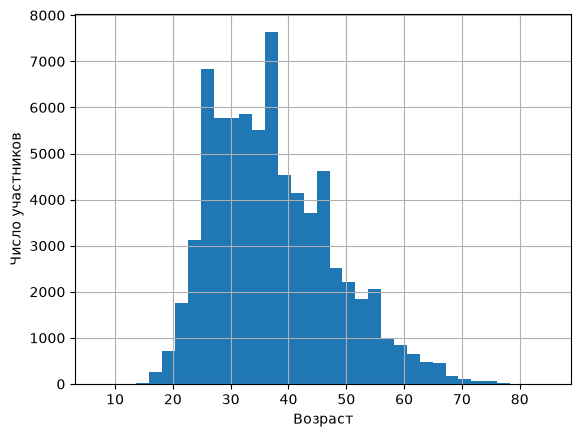

In [1]:
# Вывожу версию библиотеки: от неё могут зависеть названия параметров моделей.
print('scikit-learn:', sklearn.__version__)

# Я читаю исходные данные: raw — участники, peaks — справочник вершин.
raw = pd.read_csv('members.csv')
# Читаю отдельную таблицу вершин: из неё понадобится высота.
peaks = pd.read_csv('peaks.csv')

# Создаю рабочую копию и добавляю высоту вершины по общему ключу peak_id.
data = raw.copy().merge(
    # Из справочника беру только ключ вершины и её высоту, чтобы не добавлять лишние столбцы.
    peaks[['peak_id', 'height_metres']],
    # Соединяю строки, у которых одинаковый код вершины peak_id.
    on='peak_id',
    # left сохраняет всех участников, даже если их вершина отсутствует в справочнике.
    how='left',
    # Проверяю: у многих участников может быть одна вершина, но ключ в peaks должен быть уникален.
    validate='many_to_one',
    # Временный столбец _merge покажет, какие строки не нашли пару при объединении.
    indicator=True,
)
# shape возвращает (число строк, число столбцов). eq(left_only) находит участников без пары в peaks.
print('До отбора:', data.drop(columns='_merge').shape, 'Вершина не найдена:', data['_merge'].eq('left_only').sum())

# Удаляю служебный столбец проверки объединения: для дальнейшего анализа он уже не нужен.
data = data.drop(columns='_merge')
# Маска оставляет записи с 1950 года, заполненным и известным сезоном. & означает «И».
mask = (data['year'] >= 1950) & data['season'].notna() & (data['season'] != 'Unknown')
# Отбираю строки по маске; copy создаёт самостоятельную таблицу.
data = data.loc[mask].copy()
# Показываю размер таблицы после применения условий отбора.
print('После отбора:', data.shape)
# Среднее по 0/1 равно доле единиц. 1 минус эта доля — качество ответа «всегда неудача».
print('Доля успеха:', data.success.mean(), 'Accuracy всегда неудача:', 1 - data.success.mean())

# year // 10 * 10 переводит 2007 в 2000. mean у success — доля успехов, size — число строк.
decades = data.groupby(data.year // 10 * 10).success.agg(['mean', 'size'])
# Вывожу рассчитанные доли успеха и количество участников по десятилетиям.
display(decades)

# Гистограмма показывает распределение возрастов; bins=35 задаёт число интервалов.
data.age.hist(bins=35)
# Подписываю горизонтальную ось графика.
plt.xlabel('Возраст')
# Подписываю вертикальную ось графика.
plt.ylabel('Число участников')
# Вывожу подготовленный график в результатах ячейки.
plt.show()


**Ответ**

Я загрузила таблицы и объединила их по `peak_id`. После отбора осталось **76 098 строк** из 76 519. Для 15 строк вершина не нашлась. Я использовала `left`, чтобы не потерять этих участников, а `many_to_one` — чтобы проверить, что каждой вершине соответствует одна запись. Без проверки повторяющийся ключ в справочнике размножил бы строки участников, а с ней я получу ошибку и замечу проблему.

Я посчитала долю успехов: получилось **38,31%**. Значит, классы немного несбалансированы, и ответ «всегда неудача» уже даст accuracy **0,6169**. По десятилетиям успехов в целом стало больше: от 19,94% в 1950-х до 49,05% в 2010-х. Но рост не ровный — например, в 1970-х доля снизилась до 21,33%. Я бы не связывала всё только с улучшением подготовки: состав экспедиций и полнота записей тоже менялись.


## 2. Утечки, пропуски и новые признаки

Сначала посмотрите, как с `success` связан `highpoint_metres`. Например, сравните долю успеха у участников с заполненным и пустым `highpoint_metres` и посчитайте, у какой доли участников `highpoint_metres` совпадает с высотой вершины. Также посмотрите на `died` и `injured`. Эти столбцы и идентификаторы `expedition_id`, `member_id` в признаки не берите, но из `data` не удаляйте, они еще понадобятся.

Затем проверьте пропуски в `age`, `sex` и `height_metres`, удалите строки с ними и выведите новый размер таблицы. Редкие пропуски в `citizenship` и `expedition_role` заполните строкой `'Unknown'`.

Добавьте признак `team_size`, равный числу участников экспедиции (`groupby('expedition_id')['member_id'].transform('size')`). Считайте его после удаления пропусков, тогда он равен числу участников экспедиции, оставшихся в таблице, а не точному ее составу. Разница небольшая, пропуски убирают около 4.5% строк. Затем переведите `hired`, `solo`, `oxygen_used` в 0/1 через `astype(int)`. Числовые признаки соберите в список `num_features = ['year', 'age', 'height_metres', 'team_size', 'hired', 'solo', 'oxygen_used']` и выведите их описательную статистику.

**В выводе** объясните, почему `highpoint_metres` является утечкой, хотя формально это просто высота. Честный ли признак `oxygen_used`? Кислород планируют заранее, но отмечают по факту, а участник, который развернулся ниже высоты, где кислород обычно начинают использовать, мог так им и не воспользоваться. Почему `team_size` можно использовать, хотя он посчитан по всей таблице, включая будущую тестовую часть? Почему идентификаторы не годятся в признаки, даже если модель на них «работает»?

In [2]:
# Сравниваю долю успеха при известной и неизвестной достигнутой высоте.
display(data.groupby(data.highpoint_metres.notna()).success.agg(['mean', 'size']))
# eq сравнивает две высоты построчно; mean считает долю совпадений среди всех строк.
print('Высота совпадает с вершиной, доля всех строк:', data.highpoint_metres.eq(data.height_metres).mean())

# Проверяю связь исходов с успехом. Эти столбцы анализирую, но модели их не передаю.
for col in ['died', 'injured']:
    # Для каждого значения died или injured считаю долю успеха и число участников.
    display(data.groupby(col).success.agg(['mean', 'size']))

# isna отмечает пропуски, sum считает их по каждому столбцу.
display(data[['age', 'sex', 'height_metres']].isna().sum())

# Удаляю только строки с пропусками в трёх обязательных признаках.
data = data.dropna(subset=['age', 'sex', 'height_metres']).copy()
# Вместо удаления редких пропусков в категориях создаю категорию Unknown.
data[['citizenship', 'expedition_role']] = data[
    ['citizenship', 'expedition_role']
].fillna('Unknown')

# transform возвращает размер группы для каждой строки, сохраняя длину таблицы.
data['team_size'] = data.groupby('expedition_id').member_id.transform('size')

# Перевожу логические значения в числа: False → 0, True → 1.
for col in ['hired', 'solo', 'oxygen_used']:
    # astype(int) превращает логический столбец в целочисленный.
    data[col] = data[col].astype(int)

# Это явный список разрешённых числовых признаков. success и сведения об исходе сюда не входят.
num_features = [
    # Год проведения экспедиции.
    'year',
    # Возраст участника.
    'age',
    # Высота самой вершины, известная заранее; это не достигнутая участником высота.
    'height_metres',
    # Число записей участников данной экспедиции после очистки.
    'team_size',
    # Был ли участник нанятым работником: 0 или 1.
    'hired',
    # Было ли восхождение одиночным: 0 или 1.
    'solo',
    # Использовался ли кислород по факту: 0 или 1. Для прогноза до старта признак спорный.
    'oxygen_used',
]
print('После удаления пропусков:', data.shape)
# describe показывает число значений, среднее, разброс, минимум, квартили и максимум.
display(data[num_features].describe())


,mean,size
highpoint_metres,,
False,0.0000,21661
True,0.5355,54437


Высота совпадает с вершиной, доля всех строк: 0.37983915477410707


,mean,size
died,,
False,0.385419,75017
True,0.220167,1081


,mean,size
injured,,
False,0.386501,74388
True,0.233918,1710


age              3387
sex                 1
height_metres      15
dtype: int64

После удаления пропусков: (72696, 23)


,year,age,height_metres,team_size,hired,solo,oxygen_used
count,72696.000000,72696.000000,72696.000000,72696.000000,72696.000000,72696.000000,72696.000000
mean,2001.283592,37.356154,7936.681000,13.173490,0.191111,0.001596,0.244305
std,13.468696,10.395805,836.424887,11.250987,0.393179,0.039914,0.429677
min,1950.000000,7.000000,5407.000000,1.000000,0.000000,0.000000,0.000000
25%,1992.000000,29.000000,7138.000000,6.000000,0.000000,0.000000,0.000000
50%,2004.000000,36.000000,8167.000000,10.000000,0.000000,0.000000,0.000000
75%,2012.000000,44.000000,8850.000000,16.000000,0.000000,0.000000,0.000000
max,2019.000000,85.000000,8850.000000,92.000000,1.000000,1.000000,1.000000


**Ответ**

Я сравнила участников с заполненной и пустой `highpoint_metres`. Среди первых доля успехов **53,55%**, среди вторых — **0%**. Ещё у 37,98% всех участников достигнутая высота совпала с высотой вершины. Получается, этот столбец уже рассказывает, чем закончилось восхождение, поэтому брать его в признаки нельзя. У погибших и травмированных успехов тоже меньше — 22,02% и 23,39%, но эти сведения появляются после начала маршрута.

После удаления пропусков у меня осталось **72 696 строк**. С кислородом есть спорный момент: заранее можно знать план, но `oxygen_used` записан по факту. Человек мог развернуться раньше и так им и не воспользоваться. Я оставила признак по условию, но для прогноза до старта лучше брать именно план использования кислорода.

`team_size` я посчитала по всей таблице: он не использует `success`, а состав команды может быть известен заранее. Здесь это число участников, оставшихся после удаления пропусков, а не полный состав. Для новой экспедиции его тоже нужно получать из информации, доступной до старта. Идентификаторы я не брала: модель может просто запомнить конкретные экспедиции и показать хорошее качество только потому, что их участники попали и в обучение, и в тест.


## 3. Разбиение и первая модель

Задайте `y = data['success'].astype(int)` и разделите данные на обучающую и тестовую выборки в пропорции 75/25 командой `X_train, X_test, y_train, y_test = train_test_split(data, y, test_size=0.25, stratify=y, random_state=42)`. В `X_train` и `X_test` попадает вся таблица `data`, а не только признаки. Нужные столбцы потом выбираются внутри модели или через `X_train[num_features]`, остальные пригодятся для анализа.

Посчитайте accuracy константы `DummyClassifier(strategy='most_frequent')` на тесте. Затем обучите `Pipeline` из `StandardScaler` и `LogisticRegression(max_iter=1000)` на `num_features` и посчитайте accuracy на обучающей и тестовой выборках, CV-accuracy на обучающей и ROC-AUC на тесте. Для кросс-валидации создайте `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` и передавайте этот объект во всех следующих заданиях. Выведите `classification_report` на тесте.

**В выводе** оцените, насколько модель лучше константы по accuracy и есть ли признаки переобучения. Зачем нужен `stratify`? Зачем логистической регрессии масштабирование признаков? Подумайте о сходимости оптимизатора и о регуляризации, которая в `LogisticRegression` включена по умолчанию. Порог блока 1 требует accuracy на тесте не меньше 0.75.

In [ ]:
# Базовый классификатор для сравнения: например, всегда выбирает наиболее частый класс.
from sklearn.dummy import DummyClassifier
# Классификатор, который обучает линейную комбинацию признаков и переводит её в вероятность.
from sklearn.linear_model import LogisticRegression
# Отчёт с precision, recall, F1 и количеством объектов каждого класса.
from sklearn.metrics import classification_report
# Вычисление ROC-AUC по истинным классам и непрерывным оценкам модели.
from sklearn.metrics import roc_auc_score
# Деление обучающей выборки на фолды с сохранением долей классов.
from sklearn.model_selection import StratifiedKFold
# Обучение и проверка модели на нескольких фолдах по одной метрике.
from sklearn.model_selection import cross_val_score
# Разделение таблицы и целей на обучение и отложенный тест.
from sklearn.model_selection import train_test_split
# Объединение подготовки признаков и модели в одну последовательность.
from sklearn.pipeline import Pipeline
# Масштабирование признаков: вычитание среднего и деление на стандартное отклонение.
from sklearn.preprocessing import StandardScaler


In [3]:
# Цель: 1 — успех, 0 — неудача. Одна строка — участник конкретной экспедиции.
y = data.success.astype(int)
# 75% строк использую для обучения, 25% оставляю для итоговой проверки.
X_train, X_test, y_train, y_test = train_test_split(
    # stratify сохраняет доли классов; random_state=42 делает разбиение воспроизводимым.
    data, y, test_size=0.25, stratify=y, random_state=42
)
# Для CV делю train на 5 частей: обучаюсь на четырёх, проверяюсь на пятой; затем усредняю.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Базовая модель всегда выбирает самый частый класс из обучения — здесь неудачу.
dummy = DummyClassifier(strategy='most_frequent').fit(
    X_train[num_features], y_train
)
# Проверяю базовую модель на тесте, чтобы понимать, лучше ли её обученная регрессия.
dummy_acc = dummy.score(X_test[num_features], y_test)

# Pipeline объединяет масштабирование и модель: шаги применяются в правильном порядке.
pipe = Pipeline(
    [
        # StandardScaler вычитает среднее и делит на стандартное отклонение каждого признака.
        ('scale', StandardScaler()),
        # Регрессия учится предсказывать вероятность успеха; max_iter — верхний предел итераций оптимизатора.
        ('model', LogisticRegression(max_iter=1000, random_state=42)),
    ]
)
# fit обучает скейлер и веса регрессии только на train.
pipe.fit(X_train[num_features], y_train)

# На каждом фолде заново обучается весь Pipeline, включая скейлер: утечки из валидации нет.
base_cv = cross_val_score(
    pipe, X_train[num_features], y_train, cv=cv, scoring='accuracy'
).mean()
# score у этих классификаторов возвращает accuracy — долю правильных классов.
base_train = pipe.score(X_train[num_features], y_train)
# Считаю долю верных прогнозов на отложенных участниках, не использованных в fit.
base_test = pipe.score(X_test[num_features], y_test)
# Для ROC-AUC нужны непрерывные оценки: [:, 1] берёт вероятность класса успеха.
base_auc = roc_auc_score(
    # Сравниваю истинные классы с вероятностями успеха. Столбец 0 — неудача, столбец 1 — успех.
    y_test, pipe.predict_proba(X_test[num_features])[:, 1]
)

# Собираю метрики в одну таблицу; gap — модуль разницы train и test.
display(pd.DataFrame([dict(dummy=dummy_acc, train=base_train, cv=base_cv, test=base_test, auc=base_auc, gap=abs(base_train - base_test))]))
# Отчёт показывает precision, recall, F1 и число объектов каждого класса.
print(classification_report(y_test, pipe.predict(X_test[num_features])))
# True означает одновременное выполнение требований по accuracy и разрыву train/test.
print('Порог блока 1:', base_test >= 0.75 and abs(base_train - base_test) <= 0.02)


,dummy,train,cv,test,auc,gap
0,0.614339,0.759106,0.759198,0.760482,0.8184,0.001376


              precision    recall  f1-score   support

           0       0.77      0.87      0.82     11165
           1       0.74      0.58      0.65      7009

    accuracy                           0.76     18174
   macro avg       0.76      0.73      0.73     18174
weighted avg       0.76      0.76      0.75     18174

Порог блока 1: True


**Ответ**

Я обучила константу и логистическую регрессию. У константы accuracy **0,6143**, у регрессии на тесте — **0,7605**: получилось лучше на 14,61 процентного пункта. На обучении accuracy **0,7591**, на CV — **0,7592**, ROC-AUC на тесте — **0,8184**. Разница между обучением и тестом всего 0,0014, поэтому явного переобучения я здесь не вижу. Порог первого блока выполнен.

Я добавила `stratify`, чтобы доли классов в обеих частях были примерно одинаковыми. Масштабирование помогает оптимизатору сходиться и делает регуляризацию более сопоставимой для возраста, высоты и остальных признаков. Скейлер стоит внутри Pipeline, поэтому на каждом фолде он обучается только на своей обучающей части.


## 4. Интерпретация логистической регрессии

Для модели из задания 3 выведите веса с названиями признаков и `np.exp(coef_)`, то есть во сколько раз меняются шансы успеха при росте признака на одно стандартное отклонение. Веса лежат в `pipe[-1].coef_[0]`, свободный член в `pipe[-1].intercept_[0]`, обученный `StandardScaler` в `pipe[0]`. Сравните знаки весов `oxygen_used`, `hired` и `height_metres` с простыми долями успеха по группам (`groupby(...).success.mean()`). Высоту для этого разбейте на интервалы через `pd.cut(data['height_metres'], bins=[0, 6000, 7000, 8000, 9000])`. Крайние границы 0 и 9000 обязательны. Без них все вершины выше 8000 м, а это больше половины строк, получат NaN и выпадут из группировки.

Для одного объекта тестовой выборки посчитайте вероятность успеха вручную. Отмасштабируйте его тем же скейлером, вычислите $\sigma(\langle w, x\rangle + w_0)$ и сравните результат с `predict_proba`.

Постройте график предсказанной вероятности успеха в зависимости от `height_metres` на отрезке от 5 500 до 8 850 м с двумя кривыми, для `oxygen_used = 0` и для `oxygen_used = 1`. Остальные признаки зафиксируйте на медианах обучающей выборки.

**В выводе** объясните, что означает вес логистической регрессии и почему $e^{w_j}$ умножает шансы, а не вероятность. Почему кривые на графике не прямые и почему расстояние между ними разное на разных высотах? Совпал ли знак веса `height_metres` с тем, что видно по интервалам высоты, и если нет, то почему? Почему вклад `oxygen_used` нельзя понимать как «кислород сам по себе повышает шансы во столько-то раз»? Подумайте, кто берет кислород и на какие вершины и как связаны между собой `oxygen_used`, `hired` и `height_metres`.

In [ ]:
# Массивы и математические операции: экспонента, логарифм, поиск максимума; сокращение np.
import numpy as np


,feature,weight,odds_ratio
0,year,0.236176,1.266398
1,age,-0.229439,0.794979
2,height_metres,-0.694504,0.499322
3,team_size,0.008127,1.008160
4,hired,0.370740,1.448807
5,solo,0.076812,1.079839
6,oxygen_used,1.266719,3.549189


oxygen_used
0    0.258483
1    0.778998
Name: success, dtype: float64

hired
0    0.315715
1    0.681638
Name: success, dtype: float64

height_metres
(0, 6000]       0.597826
(6000, 7000]    0.446390
(7000, 8000]    0.246889
(8000, 9000]    0.405864
Name: success, dtype: float64

Вручную: [0.22196889] Модель: [0.22196889]


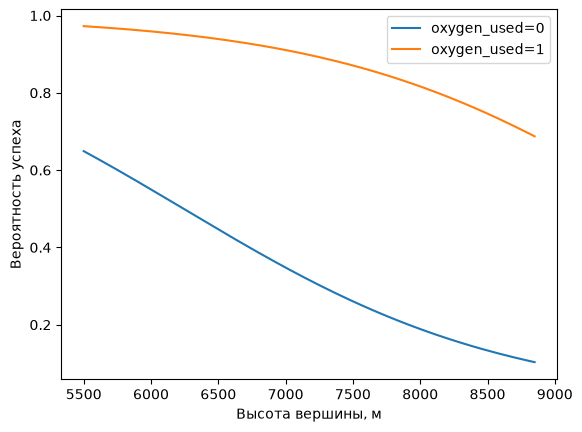

In [4]:
# pipe[-1] — последний шаг Pipeline, сама регрессия. coef_[0] содержит её веса.
weights = pd.DataFrame(
    {
        # Сохраняю названия признаков в том же порядке, в котором модель получала столбцы.
        'feature': num_features,
        # Извлекаю веса обученной регрессии: один коэффициент для каждого числового признака.
        'weight': pipe[-1].coef_[0],
        # exp(weight) — множитель ШАНСОВ p/(1-p) при росте масштабированного признака на единицу.
        'odds_ratio': np.exp(pipe[-1].coef_[0]),
    }
)
# Показываю таблицу коэффициентов и множителей шансов.
display(weights)

# Сравниваю веса модели с простыми долями успеха в группах.
for col in ['oxygen_used', 'hired']:
    # Считаю наблюдаемую долю успеха отдельно при значении 0 и 1.
    display(data.groupby(col).success.mean())
# Разбиваю высоту на интервалы. Границы 0 и 9000 включают все имеющиеся вершины.
display(data.groupby(pd.cut(data.height_metres, bins=[0, 6000, 7000, 8000, 9000]), observed=True).success.mean())

# Беру одну строку теста; двойные скобки сохраняют двумерную форму таблицы.
x = X_test[num_features].iloc[[0]]
# Применяю уже обученный скейлер: z_j = (x_j - среднее_train) / std_train.
z = pipe[0].transform(x)
# Считаю сумму w_j*z_j + свободный член, затем сигмоиду 1/(1+exp(-сумма)).
p_manual = 1 / (1 + np.exp(-(z @ pipe[-1].coef_[0] + pipe[-1].intercept_[0])))
# Получаю вероятность того же участника штатным методом модели.
p_model = pipe.predict_proba(x)[:, 1]
# Вывожу рядом два результата, чтобы убедиться, что формула реализована правильно.
print('Вручную:', p_manual, 'Модель:', p_model)
# Проверяю совпадение ручного расчёта с predict_proba с учётом погрешности чисел.
assert np.allclose(p_manual, p_model)

# Создаю 150 значений высоты для графика чувствительности модели.
heights = np.linspace(5500, 8850, 150)
# Повторяю построение графика для двух значений признака кислорода.
for oxygen in [0, 1]:
    # Остальные признаки фиксирую на медианах train. Это условный пример, не реальная группа людей.
    grid = pd.DataFrame([X_train[num_features].median()] * len(heights))
    # Меняю высоту от строки к строке, оставляя другие числовые признаки на медианах.
    grid['height_metres'] = heights
    # Строю две кривые: без кислорода и с кислородом при одинаковых остальных признаках.
    grid['oxygen_used'] = oxygen
    # Вычисляю вероятности для искусственной таблицы и рисую зависимость от высоты.
    plt.plot(heights, pipe.predict_proba(grid)[:, 1], label=f'oxygen_used={oxygen}')

# Подписываю горизонтальную ось графика.
plt.xlabel('Высота вершины, м')
# Подписываю вертикальную ось графика.
plt.ylabel('Вероятность успеха')
# Показываю легенду: она объясняет, какой линии соответствует каждый вариант.
plt.legend()
# Вывожу подготовленный график в результатах ячейки.
plt.show()


**Ответ**

Я вывела веса и отношения шансов. Например, у высоты вес **−0,6945**, а `exp(weight)` равен **0,4993**. То есть при увеличении высоты на одно стандартное отклонение шансы успеха примерно вдвое меньше, если остальные признаки зафиксированы. Это именно шансы `p / (1-p)`, а не сама вероятность. Для кислорода вес 1,2667 и множитель 3,5492, но переход 0→1 у бинарного признака не равен одному стандартному отклонению.

Я вручную посчитала вероятность для одного участника: **0,22196889**. Она совпала с `predict_proba`. На графике линии получились изогнутыми из-за сигмоиды. Один и тот же сдвиг логарифма шансов сильнее меняет вероятность в середине шкалы и слабее около 0 и 1, поэтому расстояние между кривыми меняется.

У кислорода и найма веса положительные, и простые доли тоже выше: 77,90% против 25,85% для кислорода и 68,16% против 31,57% для найма. По высоте доли идут не монотонно: 59,78%, 44,64%, 24,69% и 40,59%. Отрицательный вес высоты описывает её связь при учёте остальных признаков, а групповые доли смешивают разные команды и условия. Поэтому я не стала бы говорить, что кислород сам по себе увеличивает успех во столько-то раз: важны и выбранная вершина, и состав команды, и то, как записан признак.


# Блок 2
Разбиение на обучающую и тестовую выборки остается тем же, что в задании 3.

### Справка к блоку 2

**Категориальные признаки** кодируются так же, как в семинаре 2. `ColumnTransformer` применяет `OneHotEncoder(handle_unknown='ignore')` к категориям и `StandardScaler` к числам, после него в `Pipeline` идет модель.
```python
prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
                          ('num', StandardScaler(), num_features)])
pipe = Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=2000))])
```

**Метрики классификации.** Матрица ошибок (`confusion_matrix`) делит объекты на четыре группы: TP (верно предсказан класс 1), FP (ложная тревога), FN (пропуск) и TN (верно предсказан класс 0).
$$\text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$
Precision показывает, какая доля предсказанных единиц действительно единицы, а recall показывает, какую долю настоящих единиц модель нашла. Обе метрики зависят от порога, по которому вероятность превращается в класс (по умолчанию 0.5). ROC-кривая показывает долю найденных единиц (TPR, это тот же recall) против доли ложных тревог (FPR) сразу при всех порогах, ROC-AUC равен площади под ней. **Balanced accuracy** - среднее recall по двум классам, у константной модели она всегда равна 0.5.

**Дисбаланс классов.** Если класс 1 встречается в 1-2% случаев, константа «всегда 0» получает accuracy 98-99% и при этом бесполезна. В такой ситуации смотрят на recall, precision, ROC-AUC и balanced accuracy, сдвигают порог или задают веса классов `class_weight='balanced'`, и тогда ошибки на редком классе входят в функцию потерь с большим весом. Существует и пересэмплирование (например, SMOTE из библиотеки `imbalanced-learn`), но здесь оно не нужно.

**Регуляризация логистической регрессии.** К log loss добавляется штраф за величину весов. В `sklearn` силу регуляризации задает обратный к ней параметр `C`, и чем меньше `C`, тем сильнее штраф (у `Ridge` и `Lasso` было наоборот, через `alpha`). L2-штраф, как в `Ridge`, сжимает все веса, L1, как в `Lasso`, обнуляет часть из них, а ElasticNet смешивает оба, и доля L1 в нем задается `l1_ratio`.

Не каждый оптимизатор (`solver`) поддерживает каждый штраф. `lbfgs` работает только с L2, `liblinear` с L1 и L2 (для бинарной задачи он быстрый), `saga` поддерживает все штрафы, включая ElasticNet. Это стохастический метод, и в задаче с L1-частью штрафа и тысячей столбцов, как здесь, он сходится медленно и требует большого `max_iter`.

**Про версии.** Начиная с `sklearn` 1.8 параметр `penalty` устарел, и тип штрафа задается одним `l1_ratio`. Значение 0 дает L2, 1 дает L1, промежуточные значения дают ElasticNet. В версии 1.10 `penalty` уберут совсем, а в 1.8 и 1.9 он еще работает, но `penalty='l1'` выдает два предупреждения, одно из них про несогласованность с `l1_ratio=0.0`, который стоит в модели по умолчанию. На результат это не влияет, но в новых версиях лучше сразу писать через `l1_ratio`. В более старых версиях, например в Colab, пишут `penalty='l1'` или `penalty='elasticnet', l1_ratio=...`, причем `l1_ratio` без `penalty='elasticnet'` там игнорируется (с предупреждением). Версию можно узнать через `sklearn.__version__`.

**Метод опорных векторов (SVM)** строит разделяющую гиперплоскость с максимальным зазором (margin) между классами. Объекты, которые лежат на границе зазора или нарушают его, называются опорными векторами, и решение определяется только ими. Функция потерь здесь hinge loss $\max(0, 1 - y \cdot a(x))$ при $y \in \{-1, +1\}$, а параметр `C`, как и в логистической регрессии, обратен силе регуляризации. `LinearSVC` - линейный SVM, он быстро обучается на больших данных. `SVC(kernel='rbf')` использует ядро и строит нелинейную границу, но время его обучения растет с числом объектов квадратично или еще быстрее. Вероятностей SVM по умолчанию не выдает, поэтому ROC-AUC считается по `decision_function(X)`.

Документация: [`confusion_matrix`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html), [`RocCurveDisplay`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html), [`balanced_accuracy_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html), [`cross_val_predict`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html), [`LinearSVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html), [`SVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html), [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

## 5. Категориальные признаки

Добавьте категориальные признаки `cat_features = ['season', 'sex', 'citizenship', 'expedition_role', 'peak_name']` и выведите число уникальных значений каждого. Посмотрите на самые редкие значения `expedition_role` и посчитайте, сколько ролей встречается в обучающей выборке ровно один раз. Соберите `Pipeline` из справки и посчитайте accuracy на обучающей выборке, CV-accuracy, accuracy и ROC-AUC на тесте, а также число признаков после кодирования (`pipe[:-1].transform(X_train).shape[1]`).

Повторите то же без `peak_name` и сведите оба варианта в одну таблицу. Оставлять ли `peak_name`, решите по CV-accuracy. Выбранный набор признаков используйте во всех следующих заданиях блока 2.

**В выводе** оцените, насколько выросло качество по сравнению с заданием 3. Стоит ли оставлять `peak_name`, если высота вершины уже есть среди числовых признаков, и что, кроме высоты, может нести название вершины? Чем опасны редкие категории? Посчитайте, сколько вершин встречается в обучающей выборке меньше 10 раз.

In [ ]:
# Разная обработка числовых и категориальных столбцов в одной модели.
from sklearn.compose import ColumnTransformer
# Превращение категорий в отдельные столбцы-индикаторы 0/1.
from sklearn.preprocessing import OneHotEncoder


In [5]:
# Категориальные признаки — названия и группы; их нельзя просто считать обычными числами.
cat_features = ['season', 'sex', 'citizenship', 'expedition_role', 'peak_name']
# nunique считает число разных ролей участников в обучении.
print('Число ролей:', X_train.expedition_role.nunique())
# Разность множеств показывает категории, которых модель не встретит при обучении.
print('Роли только в тесте:', sorted(set(X_test.expedition_role) - set(X_train.expedition_role)))


# Функция собирает одинаковую обработку данных для разных классификаторов.
def make_pipe(cats, model=None):
    # ColumnTransformer применяет разные преобразования к числовым и категориальным столбцам.
    prep = ColumnTransformer(
        [
            # Масштабирую числовые признаки; параметры скейлера берутся только из обучения.
            ('num', StandardScaler(), num_features),
            # OneHot создаёт индикаторы категорий. Неизвестная категория даёт нули в своём блоке.
            ('cat', OneHotEncoder(handle_unknown='ignore'), cats),
        ]
    )
    return Pipeline(
        [
            # Первый шаг Pipeline подготавливает данные.
            ('prep', prep),
            (
                'model',
                (
                    model
                    # Если передали свою модель, использую её; иначе создаю логистическую регрессию.
                    if model is not None
                    else LogisticRegression(max_iter=2000, random_state=42)
                ),
            ),
        ]
    )


# Сохраняю обученные модели и их метрики для сравнения.
cat_models = {}
# Создаю пустой список: сюда по очереди добавлю результаты двух вариантов.
cat_rows = []

# Проверяю два варианта: с названием вершины и без него.
for name, cats in [
    # Первый вариант включает все пять категориальных признаков.
    ('with_peak', cat_features),
    # Срез [:-1] убирает последний признак списка — название вершины.
    ('without_peak', cat_features[:-1]),
]:
    # Собираю новый Pipeline под текущий набор категориальных признаков.
    model = make_pipe(cats)
    # Оцениваю вариант на CV внутри train; именно по этой метрике выбираю признаки.
    score = cross_val_score(
        model, X_train, y_train, cv=cv, scoring='accuracy'
    ).mean()
    # Обучаю выбранную обработку и регрессию на всей обучающей части.
    model.fit(X_train, y_train)
    # Запоминаю обученную модель по имени, чтобы затем достать победителя.
    cat_models[name] = model
    # Добавляю строку метрик текущей модели в список результатов.
    cat_rows.append(
        dict(
            model=name,
            train=model.score(X_train, y_train),
            cv=score,
            test=model.score(X_test, y_test),
            auc=roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
            # Считаю число столбцов ПОСЛЕ OneHot, а не число исходных признаков.
            features=model[:-1].transform(X_train).shape[1],
        )
    )

# Превращаю список словарей в таблицу и делаю имя модели индексом строк.
cat_results = pd.DataFrame(cat_rows).set_index('model')
display(cat_results)

# idxmax возвращает название варианта с максимальной CV-accuracy.
best_cat_name = cat_results.cv.idxmax()
# Из словаря достаю модель, победившую на CV.
best_cat = cat_models[best_cat_name]
# Запоминаю набор категориальных признаков победителя для следующих экспериментов.
chosen_cats = (
    cat_features if best_cat_name == 'with_peak' else cat_features[:-1]
)
print('Выбор по CV:', best_cat_name)


Число ролей: 407
Роли только в тесте: ['2nd Sirdar', 'ABC Cook', 'Admin support', 'Advance BC Manager', 'Assistant BC Mgr', 'Assistant Cameraman', 'Asst BC Manager', 'BC Manager?', 'BC Mgr/Cameraman', 'BC Mgr/Coach', 'BC Radio Operator', 'BC Technician', 'BC only', 'C2 Cook', 'Cilmber', 'Climb Ldr (torchbearer 3)', 'Climber (Autonomous)', 'Climber (Pyramid)', 'Climber (torchbear 4)', 'Climber/Advisor', 'Climber/Film Crew', 'Climber/H-A Worker', 'Climber/Transport', 'Climbing Assistant', 'Climbing Guide (Grp 1)', 'Climbing Ldr (N Face)', 'Climbing Leader (W Peak)', 'Co-Leader (Group A)', 'Co-Leader (Group B)', 'Communications Mgr', 'Communications Officer', 'Cook at C2', 'Dep Leader & BC Manager', 'Deputy Ldr (NE Ridge)', 'Deputy Leader (French)', 'Deputy Leader (Xixa)', 'Deputy Leader I/QM', 'Deputy Leader/BC Mgr', 'Exp Doctor (C2 only)', 'Exp Doctor (W Ridge)', 'Exp Doctor 1', 'Exp Doctor/Kayaker', 'Exp Doctor/Medical Res.', 'Exp Organizer (BC)', 'Film Support', 'Film Team Liaison', '

,train,cv,test,auc,features
model,,,,,
with_peak,0.782785,0.777815,0.779465,0.850092,1001
without_peak,0.764334,0.762408,0.764664,0.828290,616


Выбор по CV: with_peak


**Ответ**

Я добавила категориальные признаки. В обучении оказалось **407 разных ролей**, а в тесте встретились и новые. Поэтому я использовала `handle_unknown='ignore'`: для неизвестной категории получается нулевой блок, и модель не падает. Но отдельный эффект такой роли она, конечно, не знает.

С названием вершины у меня получилось **1001 признак**, CV-accuracy **0,7778**, test-accuracy **0,7795** и ROC-AUC **0,8501**. Без вершины осталось 616 признаков, CV-accuracy **0,7624**, test-accuracy **0,7647** и ROC-AUC **0,8283**. Я выбрала вариант **с `peak_name` по CV**. Он заметно лучше числовой модели с accuracy 0,7605 и ROC-AUC 0,8184.

Для уже известных вершин название полезно: одной высотой все особенности маршрута не описать. Если вершина совсем новая, её коэффициента у модели нет, и обычный случайный тест этого не проверяет — я бы разделяла данные по вершинам. А прогноз через 10 лет нужно проверять по времени: снаряжение, маршруты, состав участников и частота успехов могут измениться.


## 6. Метрики классификации и несбалансированные классы

**Часть А.** Для лучшей модели задания 5 постройте матрицу ошибок на тесте, посчитайте precision, recall и F1 для класса 1 и нарисуйте ROC-кривую (`RocCurveDisplay.from_estimator`). Затем получите out-of-fold вероятности на обучающей выборке (`cross_val_predict(..., cv=cv, method='predict_proba')[:, 1]`) и по ним составьте таблицу precision и recall для порогов 0.3, 0.4, 0.5, 0.6 и 0.7.

**Часть Б.** Решите вспомогательную задачу и предскажите гибель участника. Целевая переменная берется на тех же строках, что в задании 3: `y_died_train = X_train['died'].astype(int)` и `y_died_test = X_test['died'].astype(int)`. Обучите тот же `Pipeline` дважды, с `LogisticRegression(max_iter=2000)` и с `LogisticRegression(max_iter=2000, class_weight='balanced')`. Для обеих моделей и для константы `DummyClassifier(strategy='most_frequent')` посчитайте на тесте accuracy, balanced accuracy, precision, recall и ROC-AUC и сведите в таблицу. Если модель не предсказала ни одной единицы, precision считайте с `zero_division=0`.

**В выводе** объясните, как порог влияет на precision и recall, почему они меняются в разные стороны и почему ROC-AUC от порога не зависит. Почему в части Б по accuracy модель почти не отличается от константы? Что делает `class_weight='balanced'` и чем пришлось за это заплатить? Какую метрику и какой порог вы выбрали бы для модели, которая предупреждает об опасности, и что в такой задаче хуже, ложная тревога или пропуск?

In [ ]:
# Построение ROC-кривой классификатора.
from sklearn.metrics import RocCurveDisplay
# Доля правильных предсказанных классов среди всех объектов.
from sklearn.metrics import accuracy_score
# Средняя полнота по классам, дающая им одинаковый вес независимо от численности.
from sklearn.metrics import balanced_accuracy_score
# Гармоническое среднее precision и recall.
from sklearn.metrics import f1_score
# Доля настоящих единиц среди объектов, которым модель предсказала 1.
from sklearn.metrics import precision_score
# Доля найденных моделью единиц среди всех настоящих единиц.
from sklearn.metrics import recall_score
# Получение прогноза для каждой строки от модели, которая не обучалась на этой строке.
from sklearn.model_selection import cross_val_predict


Success: precision, recall, F1: 0.7431534597309999 0.6543016122128692 0.6959028831562974


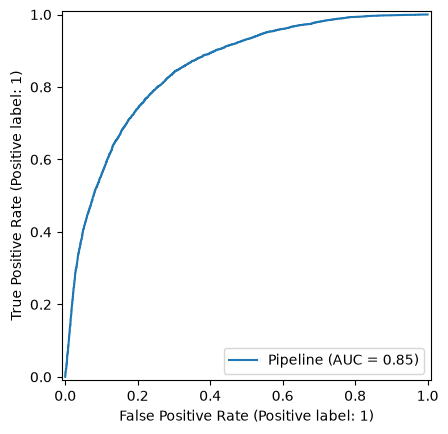

,threshold,precision,recall
0,0.3,0.629803,0.825549
1,0.4,0.693551,0.736564
2,0.5,0.739287,0.654761
3,0.6,0.782523,0.544707
4,0.7,0.821991,0.429135


,accuracy,balanced_accuracy,precision,recall,auc
model,,,,,
Dummy,0.986134,0.500000,0.000000,0.000000,0.500000
LR,0.986134,0.501956,0.500000,0.003968,0.726900
LR balanced,0.719985,0.676094,0.030844,0.630952,0.729443


In [6]:
# Получаю классы успеха на тесте при стандартном пороге 0.5.
pred = best_cat.predict(X_test)
# Precision — доля настоящих успехов среди предсказанных; recall — доля найденных реальных успехов; F1 объединяет их.
print('Success: precision, recall, F1:', precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred))

# ROC-кривая показывает соотношение доли найденных единиц и ложных тревог при разных порогах.
RocCurveDisplay.from_estimator(best_cat, X_test, y_test)
# Вывожу подготовленный график в результатах ячейки.
plt.show()

# OOF: каждая строка train получает вероятность от модели, которая на этой строке не обучалась.
oof = cross_val_predict(
    best_cat, X_train, y_train, cv=cv, method='predict_proba'
)[:, 1]
# Для каждого порога сравниваю вероятность с t: ниже порог — обычно больше найденных единиц и ложных тревог.
display(pd.DataFrame([dict(threshold=t, precision=precision_score(y_train, oof >= t), recall=recall_score(y_train, oof >= t)) for t in [0.3, 0.4, 0.5, 0.6, 0.7]]))

# Отдельная вспомогательная задача: теперь 1 означает гибель, а разбиение строк остаётся прежним.
y_died_train = X_train.died.astype(int)
# Цель теста для новой задачи; использую тех же участников, что и в основном тесте.
y_died_test = X_test.died.astype(int)

# Подготавливаю список для сравнения трёх моделей в задаче гибели.
death_rows = []

# Сравниваю константу, обычную регрессию и регрессию с повышенным весом редкого класса.
for name, model in [
    ('Dummy', DummyClassifier(strategy='most_frequent')),
    ('LR', LogisticRegression(max_iter=2000, random_state=42)),
    (
        'LR balanced',
        LogisticRegression(
            # balanced увеличивает вклад ошибок редкого класса в обучение; строки данных не дублируются.
            max_iter=2000, class_weight='balanced', random_state=42
        ),
    ),
]:
    # make_pipe выбирает только разрешённые признаки: died используется как цель, но не как вход.
    death_pipe = make_pipe(chosen_cats, model).fit(X_train, y_died_train)
    # Получаю предсказанные классы гибели на отложенном тесте.
    pred = death_pipe.predict(X_test)
    # Сохраняю метрики текущей модели в общую таблицу.
    death_rows.append(
        dict(
            model=name,
            # Считаю долю правильных ответов по всем участникам; при редком классе она может вводить в заблуждение.
            accuracy=accuracy_score(y_died_test, pred),
            # Balanced accuracy — среднее recall по двум классам, чтобы большинство не скрывало ошибки.
            balanced_accuracy=balanced_accuracy_score(y_died_test, pred),
            # zero_division=0 возвращает 0, если модель вообще не предсказала положительный класс.
            precision=precision_score(y_died_test, pred, zero_division=0),
            # Считаю долю погибших, которых модель смогла определить как положительный класс.
            recall=recall_score(y_died_test, pred, zero_division=0),
            auc=roc_auc_score(
                y_died_test, death_pipe.predict_proba(X_test)[:, 1]
            ),
        )
    )

# Одна строка таблицы соответствует одной из трёх моделей.
death_results = pd.DataFrame(death_rows).set_index('model')
display(death_results)


**Ответ**

Для успеха я получила precision **0,7432**, recall **0,6543** и F1 **0,6959**. На OOF-прогнозах снижение порога с 0,7 до 0,3 подняло recall с **0,4291 до 0,8255**, но precision упал с **0,8220 до 0,6298**. То есть я нахожу больше реальных успехов, но и чаще ошибочно обещаю успех. Если задача — предупреждать об опасности, нужно отдельно решить, какой исход считать тревогой и какие ошибки дороже. Сам порог я бы выбирала на OOF, а не на тесте. ROC-AUC от выбранного порога не зависит: он оценивает ранжирование по непрерывным оценкам.

В задаче гибели я увидела, почему одной accuracy мало. Константа дала **0,9861**, но не нашла ни одного погибшего. У обычной LR accuracy такая же, а recall всего **0,0040**. С `class_weight='balanced'` recall вырос до **0,6310**, зато precision стал **0,0308**, accuracy **0,7200**, balanced accuracy **0,6761** и ROC-AUC **0,7294**.

Сбалансированные веса усиливают вклад редкого класса в ошибку обучения. Поэтому модель чаще подаёт тревогу, но ложных тревог тоже становится больше. Для помощи участникам я бы прежде всего смотрела на recall, при этом учитывала доступные ресурсы и допустимое число ложных тревог. Ещё полезны PR-AUC и проверка калибровки. Фактическое использование кислорода для честного прогноза до старта всё равно пришлось бы заменить планом.


## 7. Регуляризация логистической регрессии

Признаки и преобразования возьмите из лучшего варианта задания 5. Через `GridSearchCV` с `cv=cv` и `scoring='accuracy'` на обучающей выборке подберите `C` для трех видов штрафа. Для L2 (`solver='lbfgs'`) и L1 (`solver='liblinear'`) перебирайте `C` по сетке `np.logspace(-3, 2, 6)`, для ElasticNet (`solver='saga'`, `l1_ratio=0.5`) хватит `C` из `[0.1, 1]`. Постройте график CV-accuracy от `C` для L1 и L2 (`plt.semilogx`).

Сведите в таблицу для каждого штрафа лучшие параметры, CV-accuracy, accuracy и ROC-AUC на тесте и число нулевых весов из общего числа. Для L1-модели выведите 10 признаков с наибольшими по модулю весами (названия дает `get_feature_names_out()` первого шага) и для категориальных среди них посчитайте, сколько объектов обучающей выборки им соответствует.

Если `ConvergenceWarning` появляется у L1 или L2, увеличьте `max_iter`. Поиск для L1 через `liblinear` занимает около минуты, а ElasticNet через `saga` на ~55 000 объектах и ~1 000 столбцах считается около 10 минут, поэтому сетка для него маленькая. У `saga` при `max_iter=2000` предупреждение о сходимости может остаться. Увеличивать для него `max_iter` не нужно, расчет только сильно удлинится, достаточно отметить это в выводе. Поставьте `n_jobs=-1`.

**В выводе** опишите, как меняется качество при уменьшении `C` и почему при больших `C` оно почти не меняется (сравните число объектов и число признаков). Сколько весов обнулила L1 и какие признаки она убрала? Можно ли доверять самым большим весам, если за ними стоят редкие категории?

In [ ]:
# Перехват предупреждений, например о том, что оптимизатор не успел сойтись.
import warnings

# Корректное сравнение номеров версий библиотек.
from packaging.version import Version
# Тип предупреждения о том, что обучение достигло лимита итераций без сходимости.
from sklearn.exceptions import ConvergenceWarning
# Перебор гиперпараметров с выбором лучшего варианта по кросс-валидации.
from sklearn.model_selection import GridSearchCV


L2 предупреждения при refit: []


L1 предупреждения при refit: []


ElasticNet предупреждения при refit: []


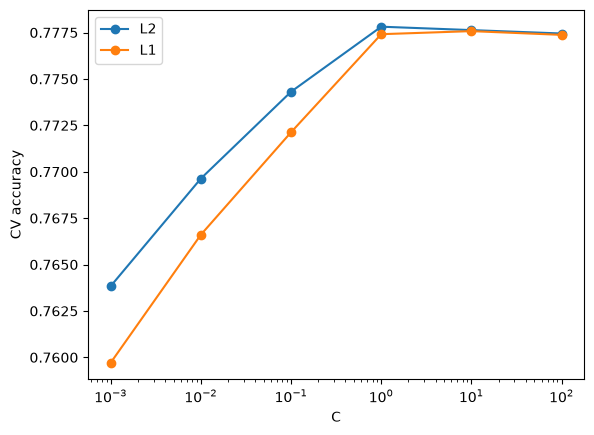

,C,cv,train,test,auc,nonzero,seconds
model,,,,,,,
L2,1.0,0.777815,0.782785,0.779465,0.850092,1001,0.874658
L1,10.0,0.777576,0.784142,0.780456,0.849993,720,23.261566
ElasticNet,1.0,0.777925,0.782583,0.779355,0.850191,588,208.026621


,weight
cat__expedition_role_Leader (2nd smt group),6.873586
cat__expedition_role_Climber (Xixa also),6.681395
cat__peak_name_Chulu West,6.331153
cat__peak_name_Manapathi NW,6.217628
cat__peak_name_Ghyun Himal I,-5.797989
cat__expedition_role_Leader & Exp Doctor,5.793142
cat__expedition_role_Climber (MM),5.706640
cat__expedition_role_Dep Ldr/Exp Doctor,5.693960
cat__peak_name_Tsaurabong Peak,5.658903
cat__peak_name_Korlang Pari Tippa,-5.430391


,zero_weight
cat__citizenship_Algeria,0.0
cat__citizenship_Andorra,0.0
cat__citizenship_Australia/USA,0.0
cat__citizenship_Bahrain,0.0
cat__citizenship_Bhutan,0.0
cat__citizenship_Bolivia,0.0
cat__citizenship_Botswana,0.0
cat__citizenship_Oman,0.0
cat__citizenship_Romania/USA,0.0
cat__citizenship_Tunisia,0.0


In [7]:
# Здесь учла, что настройка штрафа зависит от версии sklearn.


# Функция создаёт логистическую регрессию с выбранным типом регуляризации.
def logistic(kind):
    # L2 уменьшает веса; L1 может обнулить их; ElasticNet сочетает оба штрафа.
    ratio = {'L2': 0.0, 'L1': 1.0, 'ElasticNet': 0.5}[kind]
    # Собираю параметры в словарь, чтобы создать модель одним вызовом.
    params = dict(
        # Выбираю алгоритм оптимизации, совместимый с соответствующим видом штрафа.
        solver={'L2': 'lbfgs', 'L1': 'liblinear', 'ElasticNet': 'saga'}[kind],
        # Ограничиваю число итераций обучения, чтобы оптимизация не работала бесконечно.
        max_iter=2000,
        random_state=42,
    )
    # Ветка совместимости с установленной версией sklearn; для защиты важен смысл штрафов.
    if Version(sklearn.__version__) >= Version('1.8'):
        # В этой ветке доля L1 задаёт вид регуляризации: 0 — L2, 1 — L1, 0.5 — смесь.
        params['l1_ratio'] = ratio
    else:
        # В старой версии вид штрафа передаётся строковым параметром penalty.
        params['penalty'] = {
            'L2': 'l2',
            'L1': 'l1',
            'ElasticNet': 'elasticnet',
        }[kind]
        if kind == 'ElasticNet':
            params['l1_ratio'] = ratio
    # Две звёздочки распаковывают словарь в именованные аргументы конструктора модели.
    return LogisticRegression(**params)


# Создаю словарь для объектов поиска: он сохранит и параметры, и лучшие обученные модели.
searches = {}
# Создаю список для строк итоговой таблицы регуляризации.
reg_rows = []

# Сравниваю три штрафа на одинаковых признаках и одинаковых CV-разбиениях.
for kind in ['L2', 'L1', 'ElasticNet']:
    # Сетка L1/L2: 0.001, 0.01, 0.1, 1, 10, 100. Чем меньше C, тем сильнее штраф.
    values = [0.1, 1] if kind == 'ElasticNet' else np.logspace(-3, 2, 6)
    # GridSearchCV перебирает C, сравнивает среднюю CV-accuracy и переобучает победителя на всём train.
    search = GridSearchCV(
        make_pipe(chosen_cats, logistic(kind)),
        # model__C означает параметр C шага Pipeline с именем model.
        {'model__C': values},
        # Проверяю все варианты на тех же пяти разбиениях обучающей выборки.
        cv=cv,
        # Победителя определяю по средней доле верных ответов на CV.
        scoring='accuracy',
        # Разрешаю использовать все доступные процессорные ядра для параллельных расчётов.
        n_jobs=-1,
    )
    # Собираю предупреждения о сходимости при финальном обучении; сообщения рабочих CV-процессов могут идти отдельно.
    with warnings.catch_warnings(record=True) as caught:
        # Прошу регистрировать все предупреждения о несходимости, а не только первое.
        warnings.simplefilter('always', ConvergenceWarning)
        # Запускаю перебор параметров на обучающих данных.
        search.fit(X_train, y_train)
    # Сохраняю весь объект поиска для данного штрафа.
    searches[kind] = search
    # Достаю Pipeline с лучшим C; GridSearchCV уже обучил его на всём train.
    model = search.best_estimator_
    # Сохраняю C, качество, число ненулевых весов и время финального обучения.
    reg_rows.append(
        dict(
            model=kind,
            C=search.best_params_['model__C'],
            cv=search.best_score_,
            train=model.score(X_train, y_train),
            test=model.score(X_test, y_test),
            auc=roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
            # Считаю НЕнулевые коэффициенты. Число нулевых = общее число весов минус nonzero.
            nonzero=np.count_nonzero(model[-1].coef_),
            # refit_time_ — время обучения победителя, а не время всего перебора.
            seconds=search.refit_time_,
        )
    )
    print(kind, 'предупреждения при refit:', [str(w.message) for w in caught])
    # Рисую зависимость CV от C только для L1 и L2, как требуется в задании.
    if kind != 'ElasticNet':
        # По оси C использую логарифмический масштаб: соседние значения отличаются в десять раз.
        plt.semilogx(values, search.cv_results_['mean_test_score'], marker='o', label=kind)

# Подписываю горизонтальную ось графика.
plt.xlabel('C')
# Подписываю вертикальную ось графика.
plt.ylabel('CV accuracy')
# Показываю легенду: она объясняет, какой линии соответствует каждый вариант.
plt.legend()
# Вывожу подготовленный график в результатах ячейки.
plt.show()

# Формирую таблицу сравнения трёх видов регуляризации.
reg_results = pd.DataFrame(reg_rows).set_index('model')
display(reg_results)

# Извлекаю лучшую L1-модель и сопоставляю веса названиям преобразованных признаков.
l1 = searches['L1'].best_estimator_
# Создаю Series: значение — коэффициент, индекс — название соответствующего OneHot- или числового столбца.
l1_weights = pd.Series(l1[-1].coef_[0], index=l1[:-1].get_feature_names_out())
# Сортирую по модулю: большой отрицательный вес тоже означает сильный вклад модели.
display(l1_weights.loc[l1_weights.abs().sort_values(ascending=False).head(10).index].to_frame('weight'))
# Выбираю первые 15 коэффициентов, которые L1 обнулила.
display(l1_weights[l1_weights.eq(0)].head(15).to_frame('zero_weight'))


**Ответ**

Я перебрала C и получила лучшие значения: **L2 — 1, L1 — 10, ElasticNet — 1**. CV-accuracy получились 0,777815, 0,777576 и 0,777925, а accuracy на тесте — 0,779465, 0,780456 и 0,779355. Разница небольшая. У L2 осталось **1001** ненулевых весов, у L1 — **720**, у ElasticNet — **588**.

Чем больше C, тем слабее регуляризация. Весам разрешается становиться больше, а у L1 обычно меньше коэффициентов зануляется. Но качество не обязано расти: модель может начать подстраиваться под редкие категории. У L1 и L2 лучшие значения внутри сетки, у ElasticNet C=1 — на верхней границе. По этой сетке я не могу сказать, что было бы дальше: расширение могло бы дать как небольшой прирост, так и переобучение.

Среди больших положительных весов L1 я увидела редкие роли Leader (2nd smt group), Climber (Xixa also), вершины Chulu West и Manapathi NW. У Ghyun Himal I и Korlang Pari Tippa веса отрицательные. Это могут быть редкие категории с почти одинаковыми исходами, поэтому я не стала бы делать из таких весов сильные выводы. Например, веса Algeria, Andorra и Bahrain занулились: при этой регуляризации они не дали отдельного линейного вклада, но это не доказывает полное отсутствие связи.

На некоторых CV-фолдах ElasticNet достиг лимита 2000 итераций. Я сохранила этот лимит, как разрешено в задании, и учитываю, что эти оценки получены без полной сходимости. Финальное обучение ElasticNet прошло без предупреждения.


## 8. SVM и сравнение с логистической регрессией

Обучите `LinearSVC` на тех же признаках и преобразованиях, подобрав `C` из `[0.01, 0.1, 1]` через `GridSearchCV` с `cv=cv`. Выведите CV-accuracy, accuracy и ROC-AUC на тесте (ROC-AUC считайте по `decision_function`).

`SVC(kernel='rbf')` обучается на всей обучающей выборке несколько минут, а подбор `C` по кросс-валидации занял бы десятки минут. Поэтому возьмите стратифицированную подвыборку из 10 000 объектов (`X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=10000, stratify=y_train, random_state=42)`) и обучите на ней `SVC(kernel='rbf', C=1)` и, для честного сравнения, лучшую логистическую регрессию из задания 7 с теми же гиперпараметрами. Замерьте время обучения через `time.perf_counter()`, посчитайте accuracy и ROC-AUC на полном тесте и выведите число опорных векторов (`n_support_`).

Сведите модели заданий 7 и 8 в одну таблицу с размером обучающей выборки, временем обучения, CV-accuracy (где она считалась), accuracy и ROC-AUC на тесте. Время обучения моделей из `GridSearchCV` можно взять из `refit_time_`. Итоговую модель блока 2 выберите по CV-accuracy среди L2, L1 и `LinearSVC`, обученных на всей обучающей выборке, и проверьте для нее пороги блока. Accuracy на тесте должна быть не меньше 0.775, ROC-AUC не меньше 0.84, а разрыв между обучением и тестом не больше 0.02. ElasticNet в этом выборе не участвует. Через `saga` он обучается в десятки раз дольше остальных и может не сойтись, а его преимущество по CV, если оно и есть, укладывается в случайный разброс. Итоговую модель еще придется несколько раз переобучать в заданиях 11 и 12.

**В выводе** сравните функции потерь логистической регрессии и SVM и объясните, почему линейные версии дают похожее качество. Что такое опорные векторы и о чем говорит их доля среди объектов? Сравните ядровой SVM с логистической регрессией на одной и той же подвыборке. Если он выигрывает, что это говорит о зависимости успеха от признаков? Почему на этих данных ядровой SVM трудно использовать в полную силу?

In [ ]:
# Измерение времени обучения моделей.
import time

# Создание новой необученной копии модели с теми же параметрами.
from sklearn.base import clone
# Линейная модель метода опорных векторов.
from sklearn.svm import LinearSVC
# Метод опорных векторов с возможностью использовать нелинейное ядро RBF.
from sklearn.svm import SVC


In [8]:
# Линейный SVM ищет разделяющую границу с зазором; перебираю C на CV.
linear_search = GridSearchCV(
    make_pipe(
        chosen_cats, LinearSVC(max_iter=20000, dual='auto', random_state=42)
    ),
    {'model__C': [0.01, 0.1, 1]},
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
).fit(X_train, y_train)
# Достаю лучшую линейную SVM, найденную по средней CV-accuracy.
linear = linear_search.best_estimator_

# Собираю одну строку с метриками линейного SVM.
linear_row = pd.DataFrame(
    [
        dict(
            model='LinearSVC',
            C=linear_search.best_params_['model__C'],
            cv=linear_search.best_score_,
            train=linear.score(X_train, y_train),
            test=linear.score(X_test, y_test),
            # Для LinearSVC использую decision_function: это оценка положения относительно границы, не вероятность.
            auc=roc_auc_score(y_test, linear.decision_function(X_test)),
            nonzero=np.count_nonzero(linear[-1].coef_),
            seconds=linear_search.refit_time_,
        )
    ]
).set_index('model')
# Объединяю результаты в таблицу; concat дописывает строки моделей друг под другом.
comparison = pd.concat([reg_results, linear_row])

# Беру 10 000 строк ТОЛЬКО из train; доли классов сохраняю.
X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=10000, stratify=y_train, random_state=42
)

# Здесь будут результаты моделей, обученных только на 10 000 строках.
subset_rows = []
# Для сравнения на подвыборке выбираю лучшую LR по CV, здесь это ElasticNet.
best_lr_kind = reg_results.cv.idxmax()

# RBF SVM и LR обучаются на одной подвыборке и проверяются на одном полном тесте.
for name, model in [
    (
        'RBF SVM (10000)',
        make_pipe(chosen_cats, SVC(kernel='rbf', C=1, random_state=42)),
    ),
    ('LR (10000)', clone(searches[best_lr_kind].best_estimator_)),
]:
    # Замеряю фактическое время fit с помощью монотонного таймера.
    start = time.perf_counter()
    # Обучаю текущую модель на той же подвыборке, что и модель сравнения.
    model.fit(X_sub, y_sub)
    # Из времени после fit вычитаю время перед fit: получаю длительность обучения в секундах.
    seconds = time.perf_counter() - start
    # Получаю непрерывную оценку класса для ROC-AUC; это не готовый класс 0/1.
    score = model.decision_function(X_test)
    # Сохраняю качество и время текущей модели на подвыборке.
    subset_rows.append(
        dict(
            model=name,
            C=model[-1].C,
            # Для этих двух обучений отдельную CV не проводила, поэтому оставляю пропуск.
            cv=np.nan,
            train=model.score(X_sub, y_sub),
            test=model.score(X_test, y_test),
            # Для LinearSVC использую decision_function: это оценка положения относительно границы, не вероятность.
            auc=roc_auc_score(y_test, score),
            seconds=seconds,
        )
    )
    # У RBF SVM вывожу число опорных векторов по классам; они определяют границу решения.
    if isinstance(model[-1], SVC):
        print('Опорных векторов по классам:', model[-1].n_support_)

# Объединяю результаты в таблицу; concat дописывает строки моделей друг под другом.
comparison = pd.concat(
    [comparison, pd.DataFrame(subset_rows).set_index('model')]
)
display(comparison)

# Итог блока выбираю по CV среди L2, L1 и LinearSVC. ElasticNet исключён по условию.
final_name = comparison.loc[['L2', 'L1', 'LinearSVC'], 'cv'].idxmax()
# Сохраняю победителя, чтобы далее сравнить его с деревом и проверить другие разбиения.
final_model = (
    linear
    if final_name == 'LinearSVC'
    else searches[final_name].best_estimator_
)
# Достаю строку метрик модели, выбранной по CV.
final_metrics = comparison.loc[final_name]
print('Итоговая модель блока 2:', final_name)
# Проверяю три требования блока: тестовую accuracy, ROC-AUC и разрыв качества train/test.
print('Accuracy >= .775:', final_metrics.test >= 0.775, 'AUC >= .84:', final_metrics.auc >= 0.84, 'Разрыв <= .02:', abs(final_metrics.train - final_metrics.test) <= 0.02)


Опорных векторов по классам: [2747 2453]


,C,cv,train,test,auc,nonzero,seconds
model,,,,,,,
L2,1.0,0.777815,0.782785,0.779465,0.850092,1001.0,0.874658
L1,10.0,0.777576,0.784142,0.780456,0.849993,720.0,23.261566
ElasticNet,1.0,0.777925,0.782583,0.779355,0.850191,588.0,208.026621
LinearSVC,1.0,0.776696,0.782803,0.779520,0.849482,1001.0,4.390524
RBF SVM (10000),1.0,NaN,0.800300,0.782051,0.845759,NaN,9.648809
LR (10000),1.0,NaN,0.787500,0.771927,0.841173,NaN,22.989425


Итоговая модель блока 2: L2
Accuracy >= .775: True AUC >= .84: True Разрыв <= .02: True


**Ответ**

Я выбрала итоговую модель по CV среди L2, L1 и LinearSVC. Победила **L2 с C=1**: CV **0,777815**, train **0,782785**, test **0,779465**, ROC-AUC **0,850092**. Разрыв составил **0,00332**, все требования второго блока выполнены. LinearSVC получил CV 0,776696. ElasticNet я не включала в итоговый выбор по условию, а тест не использовала для подбора.

Логистическая регрессия минимизирует log loss и выдаёт вероятности. Линейный SVM штрафует нарушения разделяющего зазора; его `decision_function` подходит для ROC-AUC, но сама по себе не является вероятностью. Обе модели строят линейную границу в пространстве преобразованных признаков.

На одинаковой подвыборке из 10 000 строк RBF дал accuracy **0,782051**, ROC-AUC **0,845759** и обучался **9,65 с**. Лучшая по CV логистическая модель, ElasticNet, на ней дала **0,771927**, **0,841173** и **22,99 с**. Здесь RBF оказался быстрее saga, но это не значит, что он лучше масштабируется на весь датасет. Время в таблице относится к финальному обучению, а не ко всему поиску по CV.

У RBF получилось **5200 опорных векторов**: 2747 класса 0 и 2453 класса 1. Они определяют границу SVM. RBF может учитывать нелинейные зависимости, но на больших данных вычисления попарных взаимодействий быстро дорожают. Поэтому на всей базе я использовала линейный SVM, а RBF проверила на подвыборке. Сравнивать эти результаты с полным обучением нужно осторожно: там меняется ещё и объём данных.


# Блок 3

### Справка к блоку 3

**Дерево решений** рекурсивно делит выборку условиями вида «признак ≤ порог». В каждой вершине перебираются все признаки и все пороги и выбирается разбиение, которое сильнее всего уменьшает неоднородность классов (impurity). Для бинарной классификации с долями классов $p_0, p_1$ используют энтропию Шеннона $H$ или индекс Джини $G$
$$H = -\sum_k p_k \log_2 p_k, \qquad G = 1 - \sum_k p_k^2.$$
Обе величины равны нулю у «чистой» вершины и максимальны при $p_0 = p_1 = 0.5$, где энтропия равна 1 биту, а индекс Джини равен 0.5. **Прирост информации** (information gain) при разбиении вершины $R$ на $L$ и $R'$ равен
$$IG = H(R) - \frac{|L|}{|R|} H(L) - \frac{|R'|}{|R|} H(R').$$
Для Джини формула та же с $G$ вместо $H$. Кандидатами в пороги служат середины между соседними уникальными значениями признака. Дерево строится жадно, то есть в каждой вершине выбирается лучшее для нее разбиение без заглядывания вперед.

**Критерии останова** ограничивают сложность дерева. Это `max_depth` (глубина), `min_samples_split` (сколько объектов нужно, чтобы делить вершину), `min_samples_leaf` (минимум объектов в листе), `max_leaf_nodes` (число листьев) и `min_impurity_decrease` (минимальный прирост). Неограниченное дерево почти полностью запоминает обучающую выборку.

Дереву не нужно масштабирование, потому что разбиение по порогу не меняется при сдвиге и растяжении признака. OneHot-столбец дерево использует как условие «категория равна X или нет».

**Важность признаков.** `feature_importances_` (MDI, mean decrease in impurity) равна нормированной сумме уменьшений неоднородности по всем разбиениям на признаке с весами по числу объектов в вершинах. Она считается по обучающей выборке и завышает важность признаков с большим числом возможных порогов. `permutation_importance` перемешивает один столбец в отложенной выборке и смотрит, насколько упало качество. Если передать `Pipeline` исходную таблицу, перемешивается категориальный признак целиком, а не отдельные OneHot-столбцы.

**Честная оценка.** Участники одной экспедиции идут вместе и часто вместе разворачиваются, поэтому их исходы сильно связаны. При случайном разбиении участники одной экспедиции попадают и в обучение, и в тест, а сочетание `peak_name`, `year`, `season` и `team_size` часто указывает на конкретную экспедицию. Примерно у двух третей строк такое сочетание встречается только у одной экспедиции. `GroupShuffleSplit` отправляет каждую экспедицию целиком в одну из частей.

Документация: [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html), [`plot_tree`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html), [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html), [`permutation_importance`](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html), [`GroupShuffleSplit`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html), [Understanding the decision tree structure](https://scikit-learn.org/stable/auto_examples/tree/plot_unveil_tree_structure.html).

## 9. Энтропия, Джини и выбор разбиения вручную

Напишите функции `entropy(y)` и `gini(y)`, которые считают неоднородность по массиву меток 0/1, и функцию `information_gain(y, left_mask, criterion)`, которая считает прирост для разбиения на `y[left_mask]` и `y[~left_mask]`. Аргумент `criterion` здесь одна из двух первых функций. Функция `best_threshold(x, y, criterion)` должна перебирать пороги-середины между соседними уникальными значениями `x` и возвращать лучший порог и прирост для условия `x <= порог`.

Пригодятся `np.unique` и `np.bincount`. У бинарных признаков единственный порог 0.5. Простой перебор на этих данных занимает меньше секунды на признак, но при желании можно отсортировать `x` один раз и считать число единиц слева накопленной суммой (`np.cumsum`).

Посчитайте энтропию и индекс Джини целевой переменной на обучающей выборке. Для каждого признака из `num_features` найдите лучший порог и прирост по энтропии и по Джини и сведите результаты в таблицу, отсортированную по приросту. Затем обучите `DecisionTreeClassifier(max_depth=1, criterion='entropy', random_state=42)` на тех же признаках и сравните его первое разбиение (`tree_.feature[0]`, `tree_.threshold[0]`) со своим.

**В выводе** назовите признак с наибольшим приростом и объясните, почему он лучший, опираясь на доли успеха из задания 4. Совпадают ли выводы по энтропии и по Джини и почему так обычно бывает? Совпал ли ваш результат со `sklearn`? Почему жадный выбор лучшего разбиения на каждом шаге не гарантирует лучшего дерева в целом?

In [ ]:
# Классификатор, строящий последовательность разбиений по признакам.
from sklearn.tree import DecisionTreeClassifier


In [9]:
# Энтропия H = -sum(p_k * log2(p_k)): 0 у чистой группы, 1 при равных долях двух классов.
def entropy(y):
    # bincount считает количество нулей и единиц; minlength=2 сохраняет оба счётчика.
    counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
    # Для пустой группы сразу возвращаю 0: делить на нулевое число объектов нельзя.
    if counts.sum() == 0:
        # Пустая группа не вносит неоднородности в расчёт.
        return 0.0
    # Нулевые доли исключаю, чтобы не вычислять log2(0).
    p = counts[counts > 0] / counts.sum()
    # Подставляю доли классов в формулу энтропии; логарифм по основанию 2 даёт значение в битах.
    return float(-(p * np.log2(p)).sum())


# Джини G = 1 - sum(p_k**2): 0 у чистой группы, 0.5 при равных долях двух классов.
def gini(y):
    # bincount считает количество нулей и единиц; minlength=2 сохраняет оба счётчика.
    counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
    # Для пустой группы сразу возвращаю 0: делить на нулевое число объектов нельзя.
    if counts.sum() == 0:
        # Пустая группа не вносит неоднородности в расчёт.
        return 0.0
    # Подставляю доли классов в формулу Джини.
    return float(1 - ((counts / counts.sum()) ** 2).sum())


# Прирост = неоднородность родителя минус взвешенная неоднородность двух дочерних групп.
def information_gain(y, left_mask, criterion):
    # Привожу ответы к массиву NumPy, а маску левого узла — к логическому массиву.
    y, left_mask = (np.asarray(y), np.asarray(left_mask, dtype=bool))
    # Обрабатываю случай, когда входной массив ответов пуст.
    if len(y) == 0:
        # Пустая группа не вносит неоднородности в расчёт.
        return 0.0
    return (
        # Сначала беру неоднородность исходной группы до разделения.
        criterion(y)
        # Доля строк слева служит весом левого узла; ~left_mask выбирает строки справа.
        - left_mask.mean() * criterion(y[left_mask])
        # Вычитаю неоднородность правой группы, умноженную на её долю объектов.
        - (~left_mask).mean() * criterion(y[~left_mask])
    )


# Перебираю возможные пороги одного признака и выбираю максимальный прирост.
def best_threshold(x, y, criterion):
    # Перевожу значения признака и правильные ответы в массивы для вычислений.
    x, y = (np.asarray(x), np.asarray(y))
    # unique возвращает отсортированные различные значения признака.
    values = np.unique(x)
    # Если значение признака одно и то же у всех, разделить объекты по нему нельзя.
    if len(values) < 2:
        # Возвращаю отсутствие порога и нулевой выигрыш.
        return (None, 0.0)
    # Беру середины между соседними уникальными значениями; для 0/1 порог один — 0.5.
    thresholds = (values[:-1] + values[1:]) / 2
    # Для каждого порога разделяю строки условием x <= t и считаю выигрыш.
    gains = [information_gain(y, x <= t, criterion) for t in thresholds]
    # argmax возвращает позицию максимального выигрыша среди проверенных порогов.
    best = int(np.argmax(gains))
    # Возвращаю два значения: лучший порог и его выигрыш.
    return (thresholds[best], gains[best])


# Проверяю функции на простых примерах с заранее известным ответом.
assert entropy([]) == gini([]) == 0
# Проверяю численные результаты с допуском на погрешность вычислений.
assert np.isclose(entropy([0, 1]), 1) and np.isclose(gini([0, 1]), 0.5)
# Проверяю численные результаты с допуском на погрешность вычислений.
assert np.isclose(
    information_gain([0, 0, 1, 1], [True, True, False, False], entropy), 1
)
# Проверяю, что на простом примере функция выбирает единственный правильный порог 0.5.
assert best_threshold([0, 0, 1, 1], [0, 0, 1, 1], entropy)[0] == 0.5

print('Энтропия:', entropy(y_train), 'Джини:', gini(y_train))

# Создаю список результатов ручного перебора порогов.
threshold_rows = []

# Повторяю ручной поиск для каждого числового признака по обоим критериям.
for criterion in [entropy, gini]:
    # По очереди рассматриваю каждый из семи числовых признаков.
    for feature in num_features:
        # Вызываю свою функцию и распаковываю найденный порог и выигрыш.
        threshold, gain = best_threshold(X_train[feature], y_train, criterion)
        # Сохраняю название критерия, признак, порог и выигрыш в одной строке.
        threshold_rows.append(
            dict(
                criterion=criterion.__name__,
                feature=feature,
                threshold=threshold,
                gain=gain,
            )
        )

# Создаю таблицу и сортирую внутри каждого критерия по убыванию выигрыша.
threshold_table = pd.DataFrame(threshold_rows).sort_values(
    ['criterion', 'gain'], ascending=[True, False]
)
display(threshold_table)

# Дерево глубины 1 делает ровно одно разбиение; сравниваю его выбор со своим.
stump = DecisionTreeClassifier(
    max_depth=1, criterion='entropy', random_state=42
).fit(X_train[num_features], y_train)
# feature[0] — номер признака корня; threshold[0] — порог в корне обученного дерева.
print('sklearn:', num_features[stump.tree_.feature[0]], stump.tree_.threshold[0])


Энтропия: 0.9619298439220954 Джини: 0.4738447211574176


,criterion,feature,threshold,gain
6,entropy,oxygen_used,0.5,0.152389
4,entropy,hired,0.5,0.061728
0,entropy,year,2001.5,0.034793
3,entropy,team_size,17.5,0.011289
2,entropy,height_metres,8718.0,0.009132
1,entropy,age,47.5,0.006077
5,entropy,solo,0.5,0.000325
13,gini,oxygen_used,0.5,0.099813
11,gini,hired,0.5,0.041409
7,gini,year,2001.5,0.022367


sklearn: oxygen_used 0.5


**Ответ**

Я написала функции и посчитала энтропию **0,96193** и Джини **0,47384**. Лучшее разбиение в обоих случаях — **`oxygen_used ≤ 0.5`**. Прирост по энтропии получился **0,15239**, по Джини — **0,09981**. Это ожидаемо: без кислорода успехов 25,85%, с кислородом — 77,90%, то есть группы сильно различаются. Мой результат совпал со sklearn.

Порядок признаков у двух критериев тоже совпал. Оба оценивают, насколько однороднее стали дочерние узлы, хотя в других данных они могут выбрать разные разбиения. Жадный алгоритм смотрит на лучший ближайший шаг, поэтому я не могу гарантировать, что он построит лучшее дерево целиком: иногда менее выгодный первый шаг открывает более удачные следующие.


## 10. Дерево решений и критерии останова

Соберите `Pipeline` из `ColumnTransformer` (`OneHotEncoder(handle_unknown='ignore')` для всех пяти `cat_features`, `'passthrough'` для `num_features`) и `DecisionTreeClassifier(random_state=42)`.

Сначала для `max_depth` из `[1, 2, 3, 4, 6, 8, 10, 12, 15, 20, None]` посчитайте accuracy на обучающей выборке и CV-accuracy (`cross_validate(..., cv=cv, return_train_score=True)`) и постройте обе зависимости от глубины на одном графике. Отдельно выведите число листьев неограниченного дерева (`get_n_leaves()`) и его accuracy на обучающей выборке.

Затем через `GridSearchCV` подберите сочетание `max_depth` из `[6, 8, 10, 12, 15]`, `min_samples_leaf` из `[1, 10, 30, 100]` и `criterion` из `['gini', 'entropy']`, а отдельным поиском подберите `max_leaf_nodes` из `[16, 32, 64, 128, 256, 512, 1024]` без ограничения глубины. Итоговое дерево выберите по CV-accuracy из лучших моделей двух поисков.

Для итогового дерева посчитайте accuracy на обучающей выборке, accuracy и ROC-AUC на тесте и нарисуйте его верхние уровни (`plot_tree(..., max_depth=2, feature_names=pipe[0].get_feature_names_out(), filled=True)`). Все расчеты задания занимают пару минут, `n_jobs=-1` их ускорит.

**В выводе** ответьте, с какой глубины начинается переобучение и как это видно на графике. Какой критерий останова оказался полезнее? Сравните лучший вариант по `max_depth` и `min_samples_leaf` с лучшим вариантом по `max_leaf_nodes` и объясните, почему ограничение числа листьев может работать лучше ограничения глубины (дерево с `max_leaf_nodes` сначала делит самые выгодные вершины, а не весь уровень целиком). Оказалось ли лучшее значение `max_leaf_nodes` на краю сетки и что, по-вашему, стало бы с разрывом между обучением и тестом, если бы сетку расширили? Какие условия стоят в верхних вершинах и как они соотносятся с заданием 9? Лучше ли дерево логистической регрессии из блока 2 и с чем это может быть связано? Пороги блока 3 требуют accuracy на тесте не меньше 0.8, ROC-AUC не меньше 0.85 и разрыва между обучением и тестом не больше 0.05.

In [ ]:
# Кросс-валидация с возвратом нескольких результатов, в том числе качества на обучающих частях.
from sklearn.model_selection import cross_validate
# Рисование условий и узлов обученного дерева.
from sklearn.tree import plot_tree


,depth,train,cv
0,1.0,0.750431,0.750431
1,2.0,0.750431,0.750431
2,3.0,0.760762,0.760592
3,4.0,0.763375,0.762426
4,6.0,0.781368,0.776604
5,8.0,0.793308,0.782730
6,10.0,0.807871,0.787755
7,12.0,0.826148,0.790231
8,15.0,0.858745,0.790011
9,20.0,0.911870,0.787829


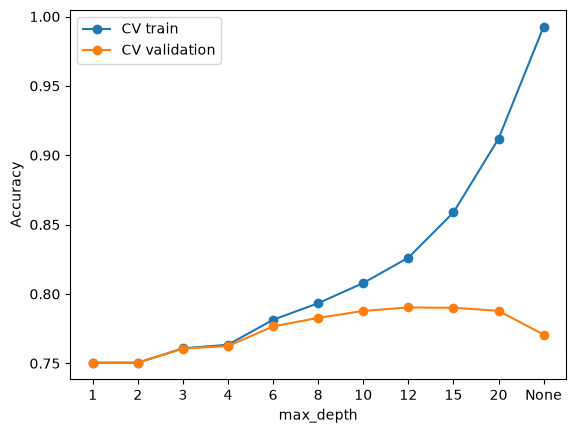

Неограниченное дерево: листьев 11848 train accuracy 0.9911411907120061


depth/leaf_size {'model__criterion': 'gini', 'model__max_depth': 12, 'model__min_samples_leaf': 1} CV: 0.7902314593822524
leaf_count {'model__max_leaf_nodes': 1024} CV: 0.7952753302297607
Итоговое дерево: {'max_leaf_nodes': 1024} {'train': 0.8425956494626022, 'test': 0.8051612193243095, 'auc': 0.8598380484128365, 'cv': np.float64(0.7952753302297607)}
Пороги блока 3: True True True


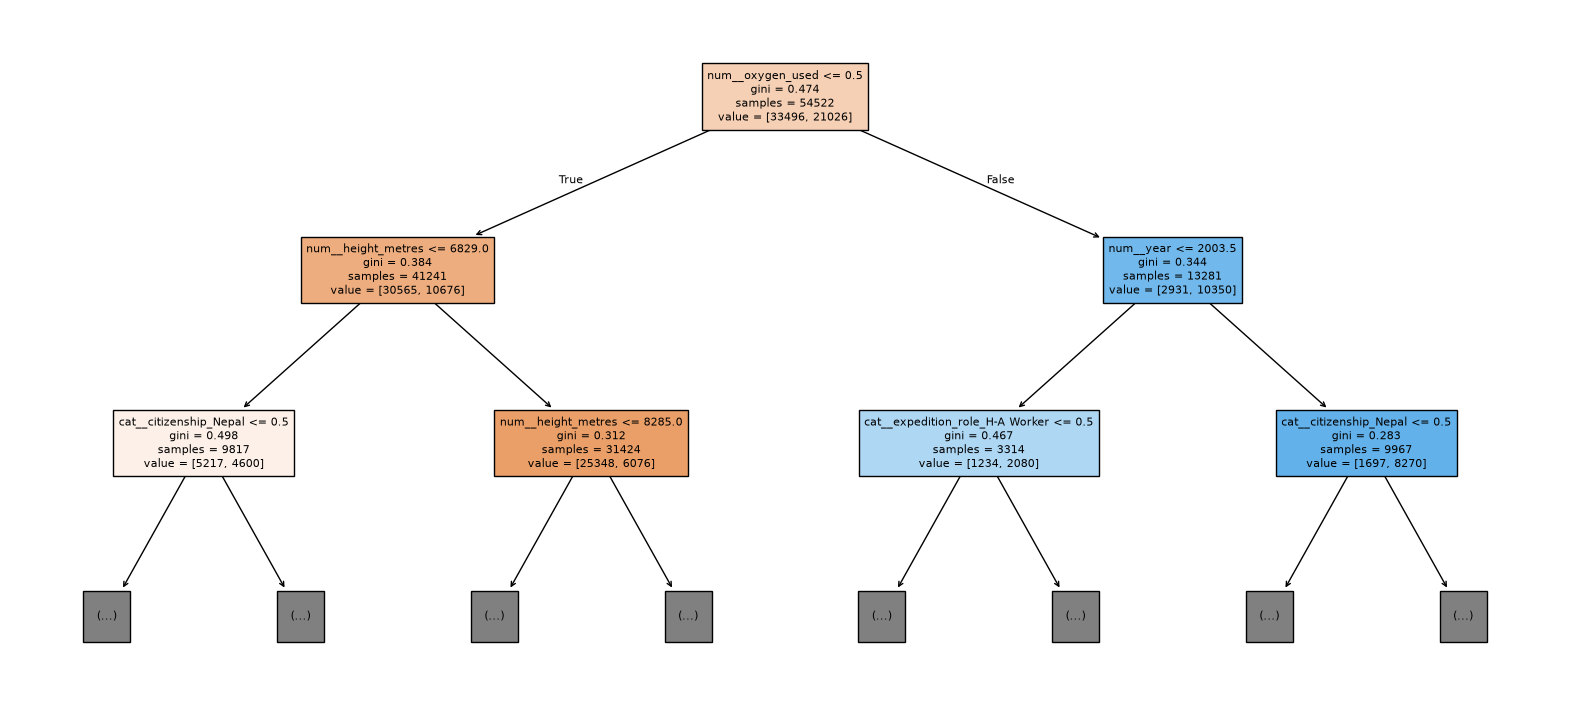

In [10]:
# Для дерева создаю отдельный Pipeline с кодированием категорий.
def tree_pipe(cats, nums, params=None):
    # Разделяю обработку категориальных и числовых столбцов.
    prep = ColumnTransformer(
        [
            # Для каждой категории создаю индикатор; незнакомую категорию обрабатываю без ошибки.
            ('cat', OneHotEncoder(handle_unknown='ignore'), cats),
            # Числа передаю без масштабирования: дерево сравнивает с порогами, единицы измерения ему не мешают.
            ('num', 'passthrough', nums),
        ]
    )
    # Возвращаю общую модель: подготовка таблицы, затем дерево решений.
    return Pipeline(
        [
            ('prep', prep),
            ('model', DecisionTreeClassifier(random_state=42, **params or {})),
        ]
    )


# Проверяю, как сложность дерева влияет на обучение и валидацию. None снимает предел глубины.
depths = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, None]
# Готовлю список качества для каждой глубины.
depth_rows = []

# Для каждой глубины обучаю дерево на пяти фолдах.
for depth in depths:
    # cross_validate возвращает отдельные оценки по всем фолдам.
    scores = cross_validate(
        tree_pipe(cat_features, num_features, {'max_depth': depth}),
        X_train,
        y_train,
        cv=cv,
        # Прошу вернуть и качество на обучающих частях фолдов, чтобы сравнить его с валидацией.
        return_train_score=True,
        scoring='accuracy',
        n_jobs=-1,
    )
    # Для текущей глубины сохраняю средние train- и validation-accuracy.
    depth_rows.append(
        dict(
            depth=depth,
            # Здесь train — средняя accuracy на обучающих частях CV, а не score на всём train.
            train=scores['train_score'].mean(),
            # test_score в cross_validate — валидационные фолды ВНУТРИ train, не отложенный X_test.
            cv=scores['test_score'].mean(),
        )
    )

# Превращаю накопленные результаты в таблицу.
depth_results = pd.DataFrame(depth_rows)
display(depth_results)

# Рисую среднюю accuracy на обучающих частях CV в зависимости от глубины.
plt.plot(range(len(depths)), depth_results.train, marker='o', label='CV train')

# На тот же график добавляю среднюю accuracy на валидационных частях CV.
plt.plot(range(len(depths)), depth_results.cv, marker='o', label='CV validation')
# Заменяю номера точек на фактические глубины; последняя подпись None — без ограничения.
plt.xticks(range(len(depths)), [str(d) for d in depths])
# Подписываю горизонтальную ось графика.
plt.xlabel('max_depth')
# Подписываю вертикальную ось графика.
plt.ylabel('Accuracy')
# Показываю легенду: она объясняет, какой линии соответствует каждый вариант.
plt.legend()
# Вывожу подготовленный график в результатах ячейки.
plt.show()

# Отдельно обучаю дерево без ограничения глубины: оно показывает риск запоминания обучения.
unlimited = tree_pipe(cat_features, num_features).fit(X_train, y_train)
# Показываю число конечных узлов и точность на обучении: слишком высокая может означать запоминание.
print('Неограниченное дерево: листьев', unlimited[-1].get_n_leaves(), 'train accuracy', unlimited.score(X_train, y_train))

# Первый поиск: глубина, минимум объектов в листе и критерий неоднородности.
depth_search = GridSearchCV(
    tree_pipe(cat_features, num_features),
    {
        # Перебираю максимально допустимую длину пути от корня к листу.
        'model__max_depth': [6, 8, 10, 12, 15],
        # Перебираю минимум обучающих объектов в каждом конечном узле.
        'model__min_samples_leaf': [1, 10, 30, 100],
        # Проверяю два критерия выбора разбиений: Джини и энтропию.
        'model__criterion': ['gini', 'entropy'],
    },
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
).fit(X_train, y_train)

# Второй поиск ограничивает общее число листьев и оставляет глубину неограниченной.
leaf_search = GridSearchCV(
    tree_pipe(cat_features, num_features),
    {'model__max_leaf_nodes': [16, 32, 64, 128, 256, 512, 1024]},
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
).fit(X_train, y_train)

# Вывожу победителя каждого из двух способов ограничения дерева.
for name, search in [
    ('depth/leaf_size', depth_search),
    ('leaf_count', leaf_search),
]:
    print(name, search.best_params_, 'CV:', search.best_score_)

# Выбираю между двумя поисками по лучшей CV-accuracy.
chosen_search = max([depth_search, leaf_search], key=lambda s: s.best_score_)
# Сохраняю лучшее обученное дерево вместе с обработкой признаков.
final_tree = chosen_search.best_estimator_
# Запоминаю параметры дерева отдельно от префикса шага Pipeline.
tree_params = {
    # Удаляю model__ из имени, например model__max_leaf_nodes превращаю в max_leaf_nodes.
    k.removeprefix('model__'): v for k, v in chosen_search.best_params_.items()
}

# Только после выбора параметров считаю качество на отложенном тесте.
tree_metrics = dict(
    train=final_tree.score(X_train, y_train),
    test=final_tree.score(X_test, y_test),
    auc=roc_auc_score(y_test, final_tree.predict_proba(X_test)[:, 1]),
    cv=chosen_search.best_score_,
)
print('Итоговое дерево:', tree_params, tree_metrics)
print('Пороги блока 3:', tree_metrics['test'] >= 0.8, tree_metrics['auc'] >= 0.85, abs(tree_metrics['train'] - tree_metrics['test']) <= 0.05)

# Задаю большой размер рисунка, чтобы подписи дерева было удобнее читать.
plt.figure(figsize=(20, 9))
# Рисую верхние уровни. Внутри дерево может быть существенно глубже max_depth=2 на рисунке.
plot_tree(
    final_tree[-1],
    max_depth=2,
    # Беру названия преобразованных столбцов в том порядке, который получало дерево.
    feature_names=final_tree[0].get_feature_names_out(),
    # Закрашиваю узлы по преобладающему классу и его доле.
    filled=True,
    fontsize=8,
)
# Вывожу подготовленный график в результатах ячейки.
plt.show()


**Ответ**

По графику я заметила, что после глубины **12** переобучение усиливается. CV-accuracy сначала дошла до **0,79023**, а на глубинах 15 и 20 снизилась до 0,79001 и 0,78783, хотя качество на обучении продолжало расти. У неограниченного дерева получилось **11 848 листьев** и train-accuracy **0,99114**, но CV всего **0,77070**.

Первый поиск выбрал gini, max_depth=12 и min_samples_leaf=1 с CV **0,79023**. Во втором лучше оказалось **max_leaf_nodes=1024**: CV **0,79528**, train **0,84260**, test **0,80516**, ROC-AUC **0,85984**. Я выбрала это дерево. Разрыв **0,03743**, так что все пороги третьего блока выполнены.

Ограничение числа листьев оказалось полезнее: дерево тратит сложность на самые выгодные ветви, а не получает одинаковый предел глубины для всех путей. Правда, 1024 — край сетки. При дальнейшем увеличении листьев модель могла бы сильнее запоминать обучение, поэтому я бы ожидала риск роста разрыва, а не гарантированный прирост.

В корне я увидела кислород ≤0,5, как в задании 9. Затем идут высота ≤6829 м без кислорода и год ≤2003,5 с кислородом; дальше встречаются Nepal, высота 8285 м и роль H-A Worker. Дерево учитывает разные пороги и сочетания признаков, поэтому на случайном тесте оно лучше L2: **0,80516 против 0,77947**. Но часть преимущества может объясняться тем, что участники одной экспедиции есть и в обучении, и в тесте.


## 11. Важность признаков и отбор признаков

Для итогового дерева задания 10 получите `feature_importances_` и сложите важности OneHot-столбцов в важность исходного признака (имена столбцов вида `cat__peak_name_Everest` начинаются с названия шага и признака). Разрезать имя по `_` не получится, подчеркивания есть и в названиях признаков вроде `peak_name`, и в самих значениях, поэтому проверяйте `startswith('cat__' + признак + '_')`. Посчитайте `permutation_importance` того же дерева на тесте по исходным столбцам с `n_repeats=5`, `scoring='accuracy'` и `random_state=42`. Передайте ему `X_test[cat_features + num_features]`, а не всю таблицу, иначе он будет зря перемешивать неиспользуемые столбцы. Третий рейтинг постройте по модулю весов итоговой линейной модели блока 2, для категориального признака берите максимум модуля по его OneHot-столбцам. Сведите три рейтинга в таблицу.

Дальше проверьте, как качество зависит от набора признаков. Для этого удобно написать функцию `make_tree(cat_cols, num_cols)`, которая собирает `Pipeline` с гиперпараметрами итогового дерева по спискам столбцов.

Начните со всех исходных признаков и повторяйте, пока не останется один признак: посчитайте CV-accuracy дерева на текущем наборе, обучите его на всей обучающей выборке и удалите самый важный по MDI признак. Постройте график CV-accuracy от числа удаленных признаков.

Затем найдите минимальный информативный набор. Начните с пустого набора и жадно добавляйте по одному исходному признаку, каждый раз тот, что дает лучшую CV-accuracy, пока она не окажется не ниже CV-accuracy модели на всех признаках минус 0.005. Выведите найденный набор. Оба перебора вместе занимают пару минут.

**В выводе** сравните три рейтинга и объясните, почему они могут не совпадать. На какой выборке считается каждая важность, как MDI относится к признакам с большим числом возможных порогов, можно ли напрямую сравнивать веса стандартизованных числовых признаков и OneHot-столбцов? Насколько падает качество после удаления самого важного признака и после следующих шагов, к какому значению оно приходит в конце (сравните с константой) и какие признаки частично заменяют удаленные? Сколько признаков вошло в минимальный набор и что это говорит о задаче?

In [ ]:
# Оценка полезности признаков через потерю качества после их перемешивания.
from sklearn.inspection import permutation_importance


,MDI,permutation,permutation_std,linear_max_abs,MDI_rank,permutation_rank,linear_max_abs_rank
oxygen_used,0.412156,0.158127,0.001023,1.401624,1.0,1.0,4.0
height_metres,0.171293,0.114075,0.002098,0.857673,2.0,2.0,5.0
year,0.096940,0.060559,0.001082,0.126837,3.0,3.0,10.0
citizenship,0.073384,0.021338,0.001047,1.788315,4.0,6.0,3.0
team_size,0.065357,0.031286,0.000718,0.065593,5.0,4.0,12.0
peak_name,0.060784,0.017079,0.000535,2.549287,6.0,8.0,1.0
age,0.039014,0.011621,0.001184,0.276808,7.0,9.0,9.0
hired,0.033744,0.017949,0.001207,0.310334,8.0,7.0,8.0
season,0.022096,0.024177,0.001054,0.357532,9.0,5.0,7.0
expedition_role,0.020404,0.006658,0.000817,2.220910,10.0,10.0,2.0


,removed_count,cv,next_removed
0,0,0.795275,oxygen_used
1,1,0.747662,year
2,2,0.718407,hired
3,3,0.720847,expedition_role
4,4,0.719196,citizenship
5,5,0.681266,team_size
6,6,0.659789,peak_name
7,7,0.658010,height_metres
8,8,0.614009,age
9,9,0.614761,season


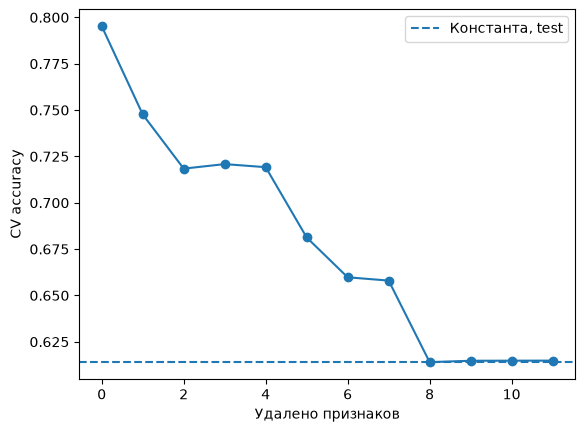

Минимальный набор жадного поиска: ['oxygen_used', 'peak_name', 'year', 'citizenship'] Целевой CV: 0.7902753302297607


,added,cv
0,oxygen_used,0.750431
1,peak_name,0.762610
2,year,0.787389
3,citizenship,0.796981


In [11]:
# Возвращаюсь к 12 исходным признакам, а не к сотням OneHot-столбцов.
all_features = cat_features + num_features


# Объединяю важности OneHot-столбцов обратно по исходным признакам.
def aggregate(values, names, cats, nums, mode='sum'):
    # Здесь будут итоговые важности исходных признаков.
    result = {}
    # Перебираю названия исходных категориальных и числовых признаков.
    for feature in cats + nums:
        # Нахожу все преобразованные столбцы нужного признака по префиксу cat__имя_ или num__имя.
        mask = np.array([name.startswith('cat__' + feature + '_') if feature in cats else name == 'num__' + feature for name in names])
        # Беру только те значения важности или веса, которые относятся к текущему признаку.
        selected = np.asarray(values)[mask]
        # Для MDI складываю вклады всех категорий; для весов беру максимум из переданных модулей.
        result[feature] = (
            (selected.max() if mode == 'max' else selected.sum())
            if len(selected)
            else 0.0
        )
    # Возвращаю одномерную таблицу с названиями признаков в индексе.
    return pd.Series(result)


# MDI — накопленное снижение неоднородности в дереве на обучении; категории суммируются.
mdi = aggregate(
    final_tree[-1].feature_importances_,
    final_tree[0].get_feature_names_out(),
    cat_features,
    num_features,
)

# Пять раз перемешиваю каждый исходный столбец теста и измеряю падение accuracy.
permutation = permutation_importance(
    final_tree,
    X_test[all_features],
    y_test,
    n_repeats=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
)

# Для LR беру максимум модуля веса среди категорий: это другой показатель, напрямую с MDI не сравнивается.
linear_importance = aggregate(
    abs(final_model[-1].coef_[0]),
    final_model[0].get_feature_names_out(),
    chosen_cats,
    num_features,
    'max',
)

# Объединяю разные оценки важности в одну таблицу.
importance_table = pd.DataFrame(
    {
        'MDI': mdi,
        'permutation': pd.Series(
            # Среднее падение accuracy после перемешивания признака по пяти повторениям.
            permutation.importances_mean, index=all_features
        ),
        'permutation_std': pd.Series(
            # Разброс падения accuracy между повторениями перемешивания.
            permutation.importances_std, index=all_features
        ),
        'linear_max_abs': linear_importance,
    }
)

# Для каждого способа отдельно перевожу значения важности в места рейтинга.
for col in ['MDI', 'permutation', 'linear_max_abs']:
    # Большая важность получает меньшее место; равные значения получают одинаковый минимальный ранг.
    importance_table[col + '_rank'] = importance_table[col].rank(
        ascending=False, method='min'
    )
# Вывожу таблицу в порядке убывания MDI.
display(importance_table.sort_values('MDI', ascending=False))


# Вспомогательная функция строит дерево с параметрами победителя предыдущего задания.
def make_tree(cat_cols, num_cols):
    # Передаю текущие списки признаков и сохранённые параметры конструктора дерева.
    return tree_pipe(cat_cols, num_cols, tree_params)


# Собираю дерево с выбранным набором признаков и уже подобранными параметрами.
def model_for(features):
    return make_tree(
        [c for c in cat_features if c in features],
        [c for c in num_features if c in features],
    )


# Создаю копию списка: удаление признаков не изменит исходный all_features.
remaining = all_features.copy()
# Готовлю список результатов последовательного удаления.
removal_rows = []

# На каждом шаге переобучаю модель, оцениваю CV и удаляю текущий САМЫЙ важный признак.
while remaining:
    # На каждой итерации создаю модель только с оставшимися признаками.
    model = model_for(remaining)
    # Измеряю среднюю CV-accuracy до удаления очередного признака.
    score = cross_val_score(
        model, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1
    ).mean()
    # Обучаю дерево на всём train для расчёта его текущих MDI-важностей.
    model.fit(X_train, y_train)
    # Объединяю важности OneHot-столбцов, чтобы удалять исходные признаки целиком.
    importance = aggregate(
        model[-1].feature_importances_,
        model[0].get_feature_names_out(),
        [c for c in cat_features if c in remaining],
        [c for c in num_features if c in remaining],
    )
    # Это эксперимент по потере полезной информации, поэтому удаляется максимальная важность.
    removed = importance.idxmax()
    # Запоминаю качество текущего набора и название признака, который удалю следующим.
    removal_rows.append(
        dict(
            removed_count=len(all_features) - len(remaining),
            cv=score,
            next_removed=removed,
            features=remaining.copy(),
        )
    )
    # Убираю выбранный признак; на следующем шаге дерево будет обучаться без него.
    remaining.remove(removed)

# Создаю таблицу того, как качество менялось при удалении признаков.
removal_results = pd.DataFrame(removal_rows)
display(removal_results[['removed_count', 'cv', 'next_removed']])

plt.plot(removal_results.removed_count, removal_results.cv, marker='o')
# Добавляю горизонтальную линию качества константы; это тестовая справочная оценка, не CV.
plt.axhline(dummy_acc, linestyle='--', label='Константа, test')
# Подписываю горизонтальную ось графика.
plt.xlabel('Удалено признаков')
# Подписываю вертикальную ось графика.
plt.ylabel('CV accuracy')
# Показываю легенду: она объясняет, какой линии соответствует каждый вариант.
plt.legend()
# Вывожу подготовленный график в результатах ячейки.
plt.show()

# Обратный эксперимент: начинаю с пустого набора и добавляю признаки.
selected = []
# Готовлю историю поэтапного добавления признаков.
forward_rows = []
# Допускаю снижение CV не более 0.005, то есть 0.5 процентного пункта от полного дерева.
target_cv = tree_metrics['cv'] - 0.005

# На каждом шаге проверяю все возможные добавления и беру лучшее по CV.
while len(selected) < len(all_features):
    # Здесь будут CV-оценки всех возможных одиночных добавлений к текущему набору.
    candidates = {}
    # Перебираю все исходные признаки как кандидатов на добавление.
    for feature in all_features:
        # Проверяю только ещё не выбранные признаки.
        if feature not in selected:
            # Считаю CV дерева с текущим набором плюс один новый признак.
            candidates[feature] = cross_val_score(
                # Создаю новый список, не меняя selected до выбора победителя.
                model_for(selected + [feature]),
                X_train,
                y_train,
                cv=cv,
                scoring='accuracy',
                n_jobs=-1,
            ).mean()
    # Жадный выбор: лучшее добавление сейчас не гарантирует глобально минимальный набор.
    best_feature = max(candidates, key=candidates.get)
    # Добавляю победивший признак в текущий набор.
    selected.append(best_feature)
    # Запоминаю, какой признак добавлен и какого CV-качества достигли.
    forward_rows.append(dict(added=best_feature, cv=candidates[best_feature]))
    # Останавливаюсь, как только достигну целевого качества. Тест для этого выбора не используется.
    if candidates[best_feature] >= target_cv:
        # Завершаю подбор признаков, потому что допустимое качество уже получено.
        break

print('Минимальный набор жадного поиска:', selected, 'Целевой CV:', target_cv)
display(pd.DataFrame(forward_rows))


**Ответ**

Я сравнила три рейтинга. По MDI и перестановочной важности первые три места совпали: **oxygen_used, height_metres, year**. MDI получились 0,4122, 0,1713 и 0,0969. После перемешивания этих признаков тестовая accuracy снижалась примерно на **0,1581, 0,1141 и 0,0606**. В линейной модели по максимальному модулю веса впереди peak_name, expedition_role и citizenship: большой вес отдельной редкой категории ещё не делает весь признак самым полезным.

MDI я получила на обучении: это сумма уменьшений неоднородности в дереве. Он может завышать важность признаков с большим числом порогов и категорий. Перестановочную важность я считала на тесте — она показывает потерю качества после перемешивания. Связанные признаки могут заменять друг друга, поэтому рейтинги отличаются. Линейные веса получены на обучении; числовые столбцы масштабированы, а OneHot нет, так что напрямую сравнивать их модули как общую важность нельзя.

После удаления кислорода CV упала с **0,79528 до 0,74766**, то есть на 4,76 процентного пункта. После удаления года осталось **0,71841**, а после hired — **0,72085**: падение не обязано быть ровным, потому что дерево перестраивается. Год, найм, роль и гражданство частично заменяют сведения о кислороде. В конце остался solo с CV **0,61483**, почти как константа с test-accuracy **0,61434**.

Добавляя признаки по одному, я получила набор **oxygen_used, peak_name, year, citizenship**. CV росла так: 0,75043 → 0,76261 → 0,78739 → **0,79698**. Четырёх признаков хватило, чтобы пройти порог **0,79028** и даже немного превысить исходное качество. Это минимальный набор в моём жадном поиске, а не доказанный минимум среди всех сочетаний. Повторный выбор по той же CV может немного завышать оценку. Тестовый рейтинг я использовала только для анализа, итоговую модель по нему не меняла.


## 12. Честная оценка: новые экспедиции и новые сезоны

Сначала покажите, насколько связаны исходы внутри одной экспедиции. Например, посчитайте среди экспедиций из двух и более участников долю тех, где у всех участников одинаковый `success`.

Потом сделайте еще два разбиения всей таблицы `data`. Групповое строится через `GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)` с группами `data['expedition_id']`. Его метод `split` возвращает позиции строк, а не метки, поэтому переведите их в метки через `data.index[...]`. Временное разбиение отправляет в обучение экспедиции с `year <= 2014`, а в тест экспедиции с `year >= 2015`. Все три разбиения удобно хранить в словаре вида `{'случайное': (X_train.index, X_test.index), ...}` и перебирать в цикле.

Для каждого разбиения (случайного из задания 3, группового и временного) заново обучите итоговую линейную модель блока 2 и итоговое дерево блока 3 с гиперпараметрами, подобранными на случайном разбиении. Сведите в таблицу accuracy каждой модели на обучающей и тестовой частях и accuracy на тестовой части для константы, обученной на обучающей части.

**В выводе** объясните, почему при переходе от случайного разбиения к групповому дерево теряет больше, чем линейная модель, и что именно оно могло запомнить. Какое разбиение соответствует задаче «оценить шансы участника новой экспедиции», а какое задаче «предсказать следующие сезоны»? Почему на временном разбиении разрыв между обучением и тестом выглядит иначе? Посмотрите на долю успеха и число экспедиций по годам с 2010 по 2019 и сравните константы на обучающей и тестовой частях. Учтите, что за 2019 год в базе есть только весна, а весенние сезоны 2014 и 2015 годов на Эвересте были сорваны лавиной в ледопаде Кхумбу и землетрясением в Непале.

**Итог.** В 6-8 предложениях подведите итог семинара. Какого качества удалось достичь и что дало самый большой прирост? Какая модель лучше и на каком разбиении? Какие признаки сильнее всего связаны с успехом и почему? Какие ограничения есть у выводов, как в базу попадают сведения об успехе и почему по таким данным нельзя делать причинные выводы о кислороде или найме?

In [ ]:
# Разбиение по группам, чтобы одна экспедиция не оказалась одновременно в train и test.
from sklearn.model_selection import GroupShuffleSplit


In [12]:
# Для каждой экспедиции считаю число участников и число разных исходов.
exp_stats = data.groupby('expedition_id').success.agg(['size', 'nunique'])
# Среди команд минимум из двух человек ищу долю с одинаковым success у всех.
uniform_fraction = (
    # Оставляю группы минимум из двух участников; nunique=1 означает одинаковый исход у всей команды.
    exp_stats.loc[exp_stats['size'] >= 2, 'nunique'].eq(1).mean()
)
print('Однородные экспедиции среди групп >=2:', uniform_fraction)

# Групповое разбиение целиком отправляет экспедицию в train или test: общих экспедиций нет.
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
# split возвращает ПОЗИЦИИ строк. Ниже data.index переводит их в метки исходного индекса.
train_pos, test_pos = next(gss.split(data, y, groups=data.expedition_id))

# Сравниваю случайное разбиение, новые экспедиции и будущие годы.
splits = {
    # Повторно использую исходное случайное разбиение из задания 3.
    'случайное': (X_train.index, X_test.index),
    # Выбираю строки целых экспедиций, отобранных GroupShuffleSplit.
    'групповое': (data.index[train_pos], data.index[test_pos]),
    'временное': (
        # Для прогноза будущего обучаюсь только на прошлом: до 2014 года включительно.
        data.index[data.year <= 2014],
        # Проверяю прогноз на следующих годах, начиная с 2015-го.
        data.index[data.year >= 2015],
    ),
}

# Готовлю таблицу сравнения двух моделей на трёх способах разбиения.
split_rows = []

# Для каждого разбиения переобучаю модели с теми же уже выбранными гиперпараметрами.
for split_name, (train_idx, test_idx) in splits.items():
    # loc выбирает строки по меткам индекса; y беру по тем же индексам.
    train_x, test_x = (data.loc[train_idx], data.loc[test_idx])
    # Выбираю правильные ответы ровно для тех же строк, что и признаки.
    train_y, test_y = (y.loc[train_idx], y.loc[test_idx])
    # Константа выбирает большинство только из своего train, даже если большинство в test изменилось.
    baseline = DummyClassifier(strategy='most_frequent').fit(
        train_x[num_features], train_y
    )
    # На каждом разбиении сравниваю итоговую линейную модель и итоговое дерево.
    for model_name, template in [
        ('линейная', final_model),
        ('дерево', final_tree),
    ]:
        # clone создаёт необученную копию с теми же параметрами; fit обучает её на новом train.
        fitted = clone(template).fit(train_x, train_y)
        # Сохраняю train/test-качество, качество константы, доли успеха и число экспедиций.
        split_rows.append(
            dict(
                split=split_name,
                model=model_name,
                train=fitted.score(train_x, train_y),
                test=fitted.score(test_x, test_y),
                dummy_test=baseline.score(test_x[num_features], test_y),
                # Сохраняю доли успеха, чтобы отличать переобучение от изменения состава данных во времени.
                train_success=train_y.mean(),
                test_success=test_y.mean(),
                # Считаю различные экспедиции в обучающей части, а не число участников.
                train_expeditions=train_x.expedition_id.nunique(),
                # Считаю различные экспедиции в тестовой части.
                test_expeditions=test_x.expedition_id.nunique(),
            )
        )
    # Считаю пересечение ID экспедиций: случайный тест может содержать команды из обучения.
    print(split_name, 'Общих экспедиций:', len(set(train_x.expedition_id) & set(test_x.expedition_id)))

# Формирую общую таблицу, чтобы сопоставить способы проверки.
split_results = pd.DataFrame(split_rows)
display(split_results)

# Смотрю динамику последних лет. За 2019 год представлены только весенние экспедиции.
yearly = (
    # Оставляю записи за 2010–2019 годы включительно.
    data.loc[data.year.between(2010, 2019)]
    # Объединяю участников в группы по году экспедиции.
    .groupby('year')
    .agg(
        # Для каждого года считаю долю успешных участников.
        success=('success', 'mean'),
        # Считаю число разных экспедиций за год.
        expeditions=('expedition_id', 'nunique'),
        # Считаю число строк участников за год.
        members=('member_id', 'size'),
    )
)
# Вывожу динамику, помогающую объяснить изменение доли успехов во временном тесте.
display(yearly)


Однородные экспедиции среди групп >=2: 0.5832977815699659


случайное Общих экспедиций: 7114


групповое Общих экспедиций: 0


временное Общих экспедиций: 0


,split,model,train,test,dummy_test,train_success,test_success,train_expeditions,test_expeditions
0,случайное,линейная,0.782785,0.779465,0.614339,0.385642,0.385661,9905,7429
1,случайное,дерево,0.842596,0.805161,0.614339,0.385642,0.385661,9905,7429
2,групповое,линейная,0.784666,0.769269,0.628779,0.390370,0.371221,7665,2555
3,групповое,дерево,0.847661,0.762744,0.628779,0.390370,0.371221,7665,2555
4,временное,линейная,0.777278,0.795194,0.477100,0.358665,0.522900,8725,1495
5,временное,дерево,0.839448,0.775433,0.477100,0.358665,0.522900,8725,1495


,success,expeditions,members
year,,,
2010,0.415258,407,2543
2011,0.531165,418,2583
2012,0.462807,413,2487
2013,0.507784,400,2505
2014,0.356413,368,2152
2015,0.164080,284,2255
2016,0.501148,335,2614
2017,0.606200,351,2613
2018,0.630593,354,2883


**Ответ**

Я посчитала, что у **58,33%** экспедиций с двумя и более участниками все исходы одинаковые. В случайном разбиении **7114 экспедиций** одновременно есть в train и test, в групповом и временном пересечений нет. Даже без ID дерево может узнавать экспедиции по году, вершине, сезону и размеру команды.

На случайном тесте я получила accuracy линейной модели / дерева **0,77947 / 0,80516**, на групповом — **0,76927 / 0,76274**, на временном — **0,79519 / 0,77543**. При переходе к группам дерево потеряло **4,24 процентного пункта**, линейная модель — **1,02**. Для новой экспедиции подходит групповая проверка, для следующих сезонов — временная. В реальной задаче я бы и параметры подбирала под соответствующее разбиение; здесь оставила параметры случайного разбиения по условию.

Во временном разбиении доля успехов выросла с **35,87% до 52,29%**. Константа из обучения всегда отвечает «неудача»: на train это даёт **64,13%**, а на test только **47,71%**. Если выбрать большинство уже на тесте, получится другая константа с 52,29%, но для честной настройки так делать нельзя. Поэтому то, что у линейной модели test выше train (0,79519 против 0,77728), я объясняю изменением распределения, а не отсутствием любых проблем с обобщением.

По годам я увидела доли успеха **35,64% в 2014-м, 16,41% в 2015-м и 73,70% в 2019-м**; экспедиций было 368, 284 и 171. В 2019-м есть только весна, так что сравнение с полными годами не совсем честное. Срывы сезонов 2014–2015 на Эвересте, о которых сказано в задании, объясняют часть провала, но отдельно измерить их причинный эффект по этой таблице я не могу.

**Итог.** Я начала с числовой логистической регрессии и получила accuracy **0,7605**. Добавив категории, я подняла её до **0,7795** при ROC-AUC **0,8501**, а самым важным отдельным признаком оказалось фактическое использование кислорода. На случайном разбиении лучше всего сработало дерево: accuracy **0,8052**, ROC-AUC **0,8598**. Но на новых экспедициях и будущих сезонах я получила лучшее качество у линейной модели, поэтому одной случайной проверки недостаточно. Для компактного варианта мне хватило четырёх признаков — кислорода, вершины, года и гражданства, хотя этот результат ещё требует независимой проверки. Часть успеха дерева связана с тем, что оно может узнавать участников общих экспедиций по сочетаниям признаков. Сведения об исходах попадают в архив из отчётов и интервью, поэтому полнота записей, ошибки и неполные сезоны тоже влияют на выводы. По таким наблюдательным данным я не могу утверждать, что кислород или найм сами по себе вызывают рост успеха, тем более кислород здесь записан по факту.
